# Análisis exploratorio de los datos de ordeño
## Hecho por: Yael Charles Marin

EDA del dataset anonimizado integrado. Se revisan calidad, formatos, cobertura,
distribuciones, mediciones por cuarto, incidentes y asociaciones exploratorias.
Las cifras y observaciones se recalculan al ejecutar todas las celdas.

In [1]:
from pathlib import Path
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110})
pd.set_option("display.max_columns", 45)
pd.set_option("display.max_rows", 45)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "Data" / "dataset_vacas_anonimo.csv").is_file()), None)
if raiz is None:
    raise FileNotFoundError("No se encontró Data/dataset_vacas_anonimo.csv desde el directorio actual.")
ruta = raiz / "Data" / "dataset_vacas_anonimo.csv"
df_original = pd.read_csv(ruta, encoding="utf-8", low_memory=False,
                          dtype={"id_vaca": "string", "misc_eo_po": "string"})
print(f"Archivo: {ruta.name} | Filas: {len(df_original):,} | Columnas: {df_original.shape[1]}")
display(df_original.head())

# El formato identifica la representación recibida, no la procedencia garantizada.
formato_original = pd.Series("Otro", index=df_original.index, dtype="string")
texto_fecha = df_original["main_hora_de_inicio"].astype("string")
formato_original.loc[texto_fecha.str.match(r"^\d{4}-\d{2}-\d{2}", na=False)] = "ISO"
formato_original.loc[texto_fecha.str.match(r"^\d{2}/\d{2}/\d{4}", na=False)] = "Día/mes/año"
display(df_original.assign(formato_fecha=formato_original).groupby("formato_fecha").agg(
    registros=("id_vaca", "size"), vacas=("id_vaca", "nunique"),
    accion_disponible=("main_accion", "count"), produccion_disponible=("main_produccion_kg", "count")))

Archivo: dataset_vacas_anonimo.csv | Filas: 286,217 | Columnas: 44


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg,estado_numero_de_ordeno,estado_rcs_1000_celulas_ml,estado_patada,estado_incompleto,estado_pezones_no_encontrados,estado_amd_ubre,estado_amd_pezon,media_de_los_flujos_kg_min_di,media_de_los_flujos_kg_min_dd,media_de_los_flujos_kg_min_ti,media_de_los_flujos_kg_min_td,sangre_ppm_di,sangre_ppm_dd,sangre_ppm_ti,sangre_ppm_td,conductividad_ms_cm_di,conductividad_ms_cm_dd,conductividad_ms_cm_ti,conductividad_ms_cm_td,misc_eo_po,misc_usuario,misc_destino_leche,misc_razon_de_la_desviacion,flujos_maximos_kg_min_di,flujos_maximos_kg_min_dd,flujos_maximos_kg_min_ti,flujos_maximos_kg_min_td,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,main_intervalo_de_ordeno_hh_mm,contadores_monitorizacion_vaca_ubre,contadores_monitorizacion_vaca_di,contadores_monitorizacion_vaca_dd,contadores_monitorizacion_vaca_ti,contadores_monitorizacion_vaca_td,misc_programa_de_lavado,estado_mdi
0,9e261839,01/03/2025 05:37 a. m.,Ordeño,09:58,23.960,1.000,NaN,NaN,NaN,NaN,1.000,NaN,1.260,1.740,1.860,1.620,0.000,0.000,0.000,0.000,4.920,5.160,5.480,5.210,ff24d34e,NaN,Tanque,NaN,1.740,2.160,2.400,2.100,6.110,5.560,3.330,8.960,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,9e261839,01/03/2025 07:15 p. m.,Ordeño,06:51,17.200,2.000,NaN,DI,NaN,NaN,1.000,NaN,1.140,1.800,2.040,1.740,0.000,0.000,0.000,0.000,4.580,4.840,5.260,4.880,ff24d34e,NaN,Tanque,NaN,2.100,2.340,2.520,2.280,3.230,4.860,2.690,6.420,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9e261839,02/03/2025 02:24 a. m.,Ordeño,07:23,11.130,1.000,NaN,NaN,NaN,NaN,1.000,TI,1.200,1.440,1.740,1.440,0.000,0.000,0.000,0.000,4.260,4.380,5.000,4.520,ff24d34e,NaN,Tanque,NaN,1.680,1.980,2.340,1.920,4.400,2.430,1.150,3.150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9e261839,02/03/2025 07:51 p. m.,Ordeño,08:29,20.640,2.000,NaN,NaN,NaN,NaN,1.000,NaN,1.200,1.680,1.920,1.680,0.000,0.000,0.000,0.000,4.360,4.770,5.010,4.820,ff24d34e,NaN,Tanque,NaN,2.100,2.220,2.520,2.400,5.720,4.880,3.100,6.940,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9e261839,03/03/2025 06:00 a. m.,Ordeño,05:05,9.590,1.000,NaN,NaN,NaN,NaN,1.000,NaN,1.140,1.620,1.800,1.500,0.000,0.000,0.000,0.000,4.130,4.420,4.360,4.440,ff24d34e,NaN,Tanque,NaN,1.800,2.100,2.280,1.980,2.690,2.410,1.440,3.050,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,registros,vacas,accion_disponible,produccion_disponible
formato_fecha,,,,
Día/mes/año,7249,34,7249,7016
ISO,278968,201,0,278968


## 1. Inventario y calidad de los datos

La tabla resume tipos, valores disponibles y diversidad de cada columna. Los indicadores de incidentes contienen etiquetas de cuartos y nulos; un campo vacío no se interpreta automáticamente como ausencia de un incidente.

In [2]:
## Tipo de datos, nulos y valores distintos

perfil = pd.DataFrame({
    "tipo": df_original.dtypes.astype(str),
    "no_nulos": df_original.notna().sum(),
    "nulos": df_original.isna().sum(),
    "nulos_pct": df_original.isna().mean().mul(100),
    "valores_distintos": df_original.nunique(dropna=True),
})
display(perfil)


,tipo,no_nulos,nulos,nulos_pct,valores_distintos
id_vaca,string,286217,0,0.000,207
main_hora_de_inicio,str,286217,0,0.000,285792
main_accion,str,7249,278968,97.467,3
main_duracion_mm_ss,str,286217,0,0.000,2126
main_produccion_kg,float64,285984,233,0.081,3698
estado_numero_de_ordeno,float64,285984,233,0.081,6
estado_rcs_1000_celulas_ml,float64,0,286217,100.000,0
estado_patada,str,46188,240029,83.863,15
estado_incompleto,str,34419,251798,87.975,15
estado_pezones_no_encontrados,str,34175,252042,88.060,15


La cobertura debe revisarse por formato de exportación: una columna vacía en un
bloque completo puede indicar un cambio de esquema. En particular, la ausencia
de `main_accion` no basta para descartar registros que sí contienen producción.
Los identificadores anonimizados se leen como texto para conservar ceros iniciales.


In [3]:
## Estadistica descriptiva de las variables numéricas

display(df_original.select_dtypes(include="number").describe().T)

,count,mean,std,min,25%,50%,75%,max
main_produccion_kg,"285,984.000",14.795,5.339,0.000,11.050,14.270,18.080,78.170
estado_numero_de_ordeno,"285,984.000",1.837,0.844,1.000,1.000,2.000,2.000,6.000
estado_rcs_1000_celulas_ml,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_amd_ubre,"285,984.000",0.123,0.328,0.000,0.000,0.000,0.000,1.000
media_de_los_flujos_kg_min_di,"280,758.000",1.148,0.399,0.000,0.900,1.140,1.380,4.980
media_de_los_flujos_kg_min_dd,"278,706.000",1.177,0.389,0.000,0.960,1.200,1.440,4.860
media_de_los_flujos_kg_min_ti,"281,480.000",1.166,0.489,0.000,0.900,1.140,1.440,5.100
media_de_los_flujos_kg_min_td,"274,920.000",1.124,0.467,0.000,0.840,1.140,1.440,4.980
sangre_ppm_di,"280,758.000",34.295,347.313,0.000,0.000,0.000,0.000,"8,000.000"
sangre_ppm_dd,"278,706.000",17.084,174.102,0.000,0.000,0.000,0.000,"7,999.000"


La media y la desviación estándar por sí solas no determinan la forma de una
distribución. Se revisan cuantiles, ceros y extremos en las gráficas posteriores.
Las mediciones de sangre se describen en ppm y como presencia de valores mayores
que cero, sin asignarles un significado clínico.


In [4]:
print("Columnas completamente vacías:", perfil.index[perfil.no_nulos.eq(0)].tolist())

acciones = df_original["main_accion"].fillna("Sin acción informada").value_counts().rename("eventos").to_frame()
acciones["porcentaje"] = acciones.eventos.div(len(df_original)).mul(100)
display(acciones)
display(df_original.isna().groupby(formato_original).mean().T.mul(100).rename_axis("columna"))

Columnas completamente vacías: ['estado_rcs_1000_celulas_ml']


,eventos,porcentaje
main_accion,,
Sin acción informada,278968,97.467
Ordeño,7016,2.451
Rechazada,172,0.060
Echada sin ordeñar,61,0.021


,Día/mes/año,ISO
columna,,
id_vaca,0.000,0.000
main_hora_de_inicio,0.000,0.000
main_accion,0.000,100.000
main_duracion_mm_ss,0.000,0.000
main_produccion_kg,3.214,0.000
estado_numero_de_ordeno,3.214,0.000
estado_rcs_1000_celulas_ml,100.000,100.000
estado_patada,82.080,83.909
estado_incompleto,86.012,88.026


Las proporciones de acciones incluyen explícitamente los registros sin acción
informada. La tabla de nulos por formato permite reconocer columnas incorporadas
en la exportación nueva y evita interpretar diferencias de esquema como cambios
en el comportamiento de las vacas.


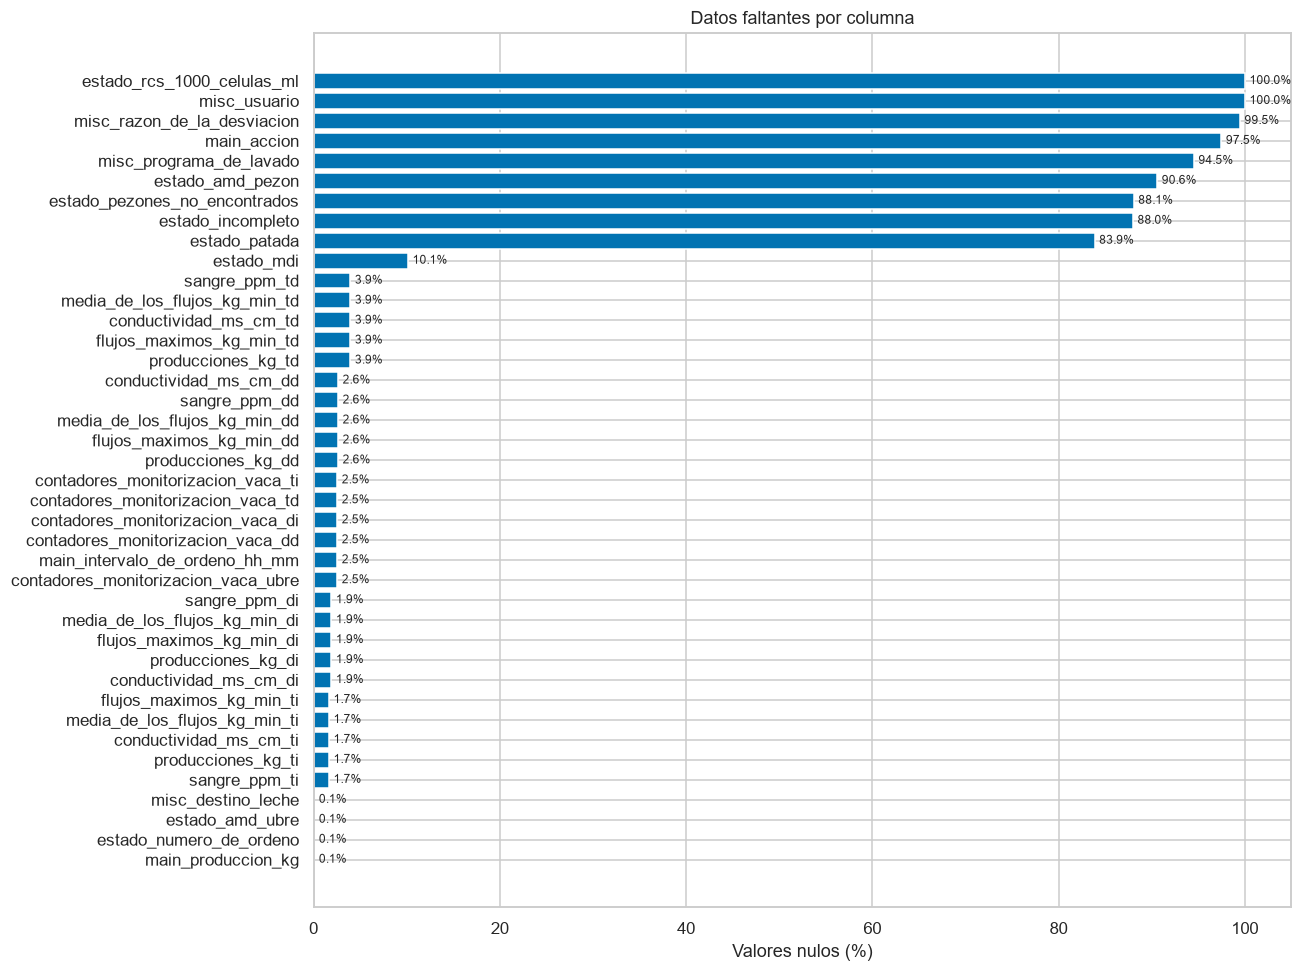

In [5]:
nulos = perfil.loc[perfil.nulos.gt(0)].sort_values("nulos_pct")
fig, ax = plt.subplots(figsize=(12, 9))
ax.barh(nulos.index, nulos.nulos_pct)
ax.set(xlabel="Valores nulos (%)", title="Datos faltantes por columna", xlim=(0, 105))
for i, v in enumerate(nulos.nulos_pct):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

Un campo de incidente vacío se interpreta como **sin etiqueta registrada**.
No demuestra que no ocurrió el incidente. Las columnas completamente vacías
se identifican a partir de la versión actual, sin conservar conclusiones de la
muestra anterior.


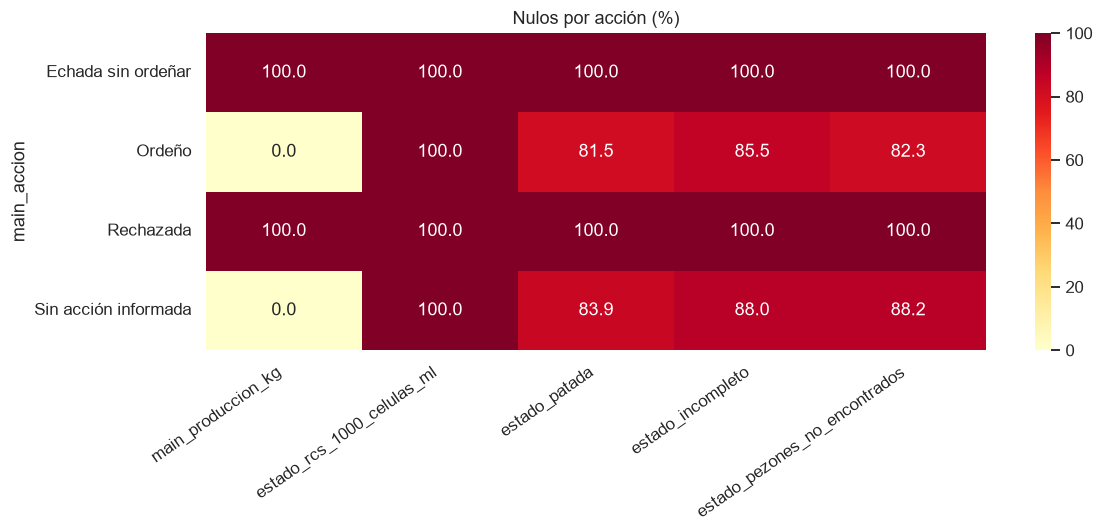

In [6]:
columnas_revision = ["main_produccion_kg", "estado_rcs_1000_celulas_ml",
    "estado_patada", "estado_incompleto", "estado_pezones_no_encontrados"]

nulos_por_accion = df_original.groupby(df_original["main_accion"].fillna("Sin acción informada"))[columnas_revision].agg(
    lambda s: s.isna().mean() * 100)
sns.heatmap(nulos_por_accion, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=100)
plt.title("Nulos por acción (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

La comparación de nulos distingue las acciones documentadas de los registros sin
acción. Los eventos rechazados o de expulsión pueden carecer de producción por el
propio flujo del equipo. Las proporciones de etiquetas de incidentes se analizan
más adelante dentro de la base de ordeños seleccionada.


### Duplicados exactos y coincidencias de identificadores

Se distinguen filas idénticas de coincidencias en `(id_vaca, main_hora_de_inicio)`.
Una hora registrada al minuto puede agrupar eventos distintos. Primero se retiran
copias exactas; después de convertir fechas y duraciones se aplica una regla
adicional, explícita y configurable para coincidencias entre exportaciones.

In [7]:
clave = ["id_vaca", "main_hora_de_inicio"]
duplicados_exactos = df_original.duplicated()
coincidencias_clave = df_original.duplicated(clave, keep=False)

print(f"Copias exactas adicionales: {duplicados_exactos.sum()}")
print(f"Filas involucradas en duplicados exactos: {df_original.duplicated(keep=False).sum()}")
print(f"Coincidencias adicionales en vaca y hora: {df_original.duplicated(clave).sum()}")

display(df_original.loc[df_original.duplicated(keep=False),
    clave + ["main_accion", "main_duracion_mm_ss", "main_produccion_kg"]].head(30))

display(df_original.loc[coincidencias_clave,
    clave + ["main_accion", "main_duracion_mm_ss", "main_produccion_kg"]]
    .sort_values(clave).head(30))

df = df_original.drop_duplicates().copy()
df["formato_fecha"] = formato_original.loc[df.index]
print(f"Base exploratoria después de quitar copias exactas: {len(df):,} eventos")

Copias exactas adicionales: 2
Filas involucradas en duplicados exactos: 4
Coincidencias adicionales en vaca y hora: 25


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg
541,cfbafffc,06/05/2025 02:46 p. m.,Rechazada,00:00,NaN
542,cfbafffc,06/05/2025 02:46 p. m.,Rechazada,00:00,NaN
3125,78f46d32,28/05/2025 07:30 a. m.,Rechazada,00:00,NaN
3126,78f46d32,28/05/2025 07:30 a. m.,Rechazada,00:00,NaN


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg
2118,01784b0a,16/03/2025 06:31 a. m.,Ordeño,08:06,16.570
2119,01784b0a,16/03/2025 06:31 a. m.,Echada sin ordeñar,08:05,NaN
5004,080047a3,16/03/2025 03:37 a. m.,Ordeño,07:13,23.550
5005,080047a3,16/03/2025 03:37 a. m.,Echada sin ordeñar,07:13,NaN
3580,2a319e33,16/03/2025 03:09 a. m.,Ordeño,07:29,11.280
3581,2a319e33,16/03/2025 03:09 a. m.,Echada sin ordeñar,07:28,NaN
4972,2a4248d4,16/07/2025 03:20 p. m.,Ordeño,00:55,0.000
4973,2a4248d4,16/07/2025 03:20 p. m.,Rechazada,00:54,NaN
4974,2a4248d4,16/07/2025 03:23 p. m.,Ordeño,09:55,1.230
4975,2a4248d4,16/07/2025 03:23 p. m.,Rechazada,09:55,NaN


Base exploratoria después de quitar copias exactas: 286,215 eventos


Las copias exactas adicionales se retiran únicamente de la base exploratoria.
La clave de fecha textual todavía mezcla precisión al minuto y al segundo;
después de convertirla se revisan también las coincidencias entre exportaciones.
Una coincidencia de vaca y hora por sí sola no implica que dos eventos sean iguales.


## 2. Fechas, duración y validaciones de coherencia

Se aceptan fechas `dd/mm/aaaa` con `a. m.` / `p. m.` y fechas ISO
`aaaa-mm-dd hh:mm:ss`. No se usa inferencia ambigua de mes y día. Se conserva la
hora local tal como se recibió, sin asignar una zona horaria no documentada.

La duración acepta `mm:ss` y `hh:mm:ss`. El intervalo entre ordeños acepta
`hh:mm` y `hh:mm:ss`. Algunos intervalos de Excel llegaron como fechas de 1900:
se reconstruye el número de días del sistema Excel 1900 (verificado en el XLSX
de origen), incluyendo su ajuste de calendario a partir de marzo. Una fecha
`1900-01-01 01:00:00` representa así 25 horas. No es una fecha del ordeño.
Los valores ausentes y los errores de conversión se reportan por separado.


In [8]:
def convertir_fechas(serie):
    texto = (serie.astype("string").str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.replace(r"(?i)a\.\s*m\.", "AM", regex=True)
        .str.replace(r"(?i)p\.\s*m\.", "PM", regex=True))
    resultado = pd.Series(pd.NaT, index=serie.index, dtype="datetime64[ns]")
    formatos = ["%d/%m/%Y %I:%M %p", "%d/%m/%Y %I:%M:%S %p",
                "%d/%m/%Y %H:%M", "%d/%m/%Y %H:%M:%S",
                "%Y-%m-%d %H:%M:%S", "%Y-%m-%d %H:%M:%S.%f",
                "%Y-%m-%dT%H:%M:%S"]
    for formato in formatos:
        pendientes = resultado.isna() & texto.notna()
        resultado.loc[pendientes] = pd.to_datetime(
            texto.loc[pendientes], format=formato, errors="coerce")
    return resultado


def convertir_tiempo(serie, dos_partes="mm:ss", excel=False):
    """Devuelve segundos; valida minutos/segundos y conserva horas > 24."""
    texto = serie.astype("string").str.strip()
    resultado = pd.Series(np.nan, index=serie.index, dtype=float)
    tres = texto.str.extract(r"^(\d+):([0-5]\d):([0-5]\d)$").astype(float)
    resultado = tres[0] * 3600 + tres[1] * 60 + tres[2]
    dos = texto.str.extract(r"^(\d+):([0-5]\d)$").astype(float)
    factor = 60 if dos_partes == "mm:ss" else 3600
    resultado = resultado.fillna(dos[0] * factor + dos[1] * factor / 60)
    if excel:
        fechas_excel = pd.to_datetime(texto.where(texto.str.match(r"^1900-", na=False)),
                                     format="%Y-%m-%d %H:%M:%S", errors="coerce")
        serial = (fechas_excel - pd.Timestamp("1899-12-31")).dt.total_seconds()
        serial += fechas_excel.ge(pd.Timestamp("1900-03-01")).astype(int) * 86400
        resultado = resultado.fillna(serial)
    return resultado


df["fecha_hora"] = convertir_fechas(df["main_hora_de_inicio"])
df["duracion_min"] = convertir_tiempo(df["main_duracion_mm_ss"]) / 60
df["intervalo_declarado_h"] = convertir_tiempo(
    df["main_intervalo_de_ordeno_hh_mm"], dos_partes="hh:mm", excel=True) / 3600
df["fecha"] = df.fecha_hora.dt.normalize()
df["hora"] = df.fecha_hora.dt.hour
df["mes"] = df.fecha_hora.dt.to_period("M")
df["fecha_minuto"] = df.fecha_hora.dt.floor("min")

conversiones = [("main_hora_de_inicio", "fecha_hora"),
               ("main_duracion_mm_ss", "duracion_min"),
               ("main_intervalo_de_ordeno_hh_mm", "intervalo_declarado_h")]
errores_conversion = []
for original, convertido in conversiones:
    presentes = df[original].notna() & df[original].astype("string").str.strip().ne("")
    fallos = presentes & df[convertido].isna()
    errores_conversion.append({"columna": original, "ausentes": int((~presentes).sum()),
                               "convertidos": int(df[convertido].notna().sum()),
                               "no_interpretables": int(fallos.sum())})
    if fallos.any():
        display(df.loc[fallos, ["id_vaca", original]].head(10))
display(pd.DataFrame(errores_conversion).set_index("columna"))
print(f"Periodo: {df.fecha_hora.min()} a {df.fecha_hora.max()}")
print(f"Vacas: {df.id_vaca.nunique()} | Códigos de equipo: {df.misc_eo_po.nunique()}")

# Inclusión explícita: no rellenamos main_accion ni equiparamos sus nulos a una etiqueta.
accion_ordeno = df["main_accion"].eq("Ordeño")
accion_ausente = df["main_accion"].isna() | df["main_accion"].astype("string").str.strip().eq("").fillna(False)
compatible = accion_ausente & df["main_produccion_kg"].notna()
df["criterio_inclusion"] = "Fuera de la base de ordeños"
df.loc[accion_ordeno, "criterio_inclusion"] = "Ordeño explícito"
df.loc[compatible, "criterio_inclusion"] = "Producción con acción no informada"

# Coincidencias entre formatos: correspondencia uno a uno, mismos datos compartidos.
# Conductividad: tolerancia de 0.005 mS/cm porque el bloque antiguo redondea a 2 decimales.
claves_exportacion = ["id_vaca", "fecha_minuto", "misc_eo_po", "main_produccion_kg", "duracion_min"]
antiguos = df.loc[df.formato_fecha.eq("Día/mes/año") & accion_ordeno].dropna(subset=claves_exportacion)
nuevos = df.loc[df.formato_fecha.eq("ISO") & compatible].dropna(subset=claves_exportacion)
pares = antiguos.reset_index(names="fila_antigua").merge(
    nuevos.reset_index(names="fila_nueva"), on=claves_exportacion, suffixes=("_ant", "_nuevo"))
coinciden = (~pares.fila_antigua.duplicated(keep=False) & ~pares.fila_nueva.duplicated(keep=False))
columnas_compartidas = [c for c in df_original.columns
    if c not in claves_exportacion + ["main_hora_de_inicio", "main_duracion_mm_ss", "main_accion"]
    and antiguos[c].notna().any() and nuevos[c].notna().any()]
for columna in columnas_compartidas:
    a, b = pares[columna + "_ant"], pares[columna + "_nuevo"]
    iguales = a.eq(b).fillna(False) | (a.isna() & b.isna())
    if columna.startswith("conductividad_"):
        iguales |= a.sub(b).abs().le(0.005 + 1e-9)
    coinciden &= iguales
pares_exportacion = pares.loc[coinciden, ["fila_antigua", "fila_nueva"] + claves_exportacion].copy()
df["coincidencia_exportacion"] = df.index.isin(pares_exportacion.fila_antigua)

# Cambiar a False permite repetir el EDA conservando ambas exportaciones.
EXCLUIR_COINCIDENCIAS_EXPORTACION = True
base_inclusion = accion_ordeno | compatible
ordenos_antes = df.loc[base_inclusion].copy()
excluir = df.coincidencia_exportacion & EXCLUIR_COINCIDENCIAS_EXPORTACION
ordenos = df.loc[base_inclusion & ~excluir].copy()
sensibilidad = pd.DataFrame({
    "incluyendo_coincidencias": [len(ordenos_antes), ordenos_antes.main_produccion_kg.sum(), ordenos_antes.main_produccion_kg.mean()],
    "base_seleccionada": [len(ordenos), ordenos.main_produccion_kg.sum(), ordenos.main_produccion_kg.mean()],
}, index=["registros", "produccion_total_kg", "produccion_media_kg"])
display(sensibilidad)
display(ordenos.criterio_inclusion.value_counts().to_frame("registros"))
print(f"Pares entre exportaciones que cumplen la regla: {len(pares_exportacion):,}.")
print("Se conserva la fila ISO con precisión de segundos; las filas originales permanecen en df_original y df.")
display(pares_exportacion.head(10))

cuartos = ["di", "dd", "ti", "td"]
columnas_cuartos = [f"producciones_kg_{q}" for q in cuartos]
ordenos["suma_cuartos_kg"] = ordenos[columnas_cuartos].sum(axis=1, min_count=4)
ordenos["diferencia_total_kg"] = ordenos.main_produccion_kg - ordenos.suma_cuartos_kg
mediciones = [c for c in df_original.select_dtypes(include="number").columns
              if c.startswith(("main_produccion", "media_de_los_flujos", "sangre_",
                               "conductividad_", "flujos_maximos_", "producciones_"))]
validaciones = pd.Series({
    "registros incluidos sin producción": ordenos.main_produccion_kg.isna().sum(),
    "registros incluidos con producción cero": ordenos.main_produccion_kg.eq(0).sum(),
    "registros incluidos con duración cero": ordenos.duracion_min.eq(0).sum(),
    "filas con alguna medición negativa": df[mediciones].lt(0).any(axis=1).sum(),
    "registros con cuatro producciones disponibles": ordenos.suma_cuartos_kg.notna().sum(),
    "diferencia total vs suma > 0.05 kg": ordenos.diferencia_total_kg.abs().gt(0.05 + 1e-9).sum(),
})
display(validaciones.to_frame("filas"))


,ausentes,convertidos,no_interpretables
columna,,,
main_hora_de_inicio,0,286215,0
main_duracion_mm_ss,0,286215,0
main_intervalo_de_ordeno_hh_mm,7247,278968,0


Periodo: 2022-07-13 00:05:28 a 2026-01-28 11:47:54
Vacas: 207 | Códigos de equipo: 4


,incluyendo_coincidencias,base_seleccionada
registros,"285,984.000","280,699.000"
produccion_total_kg,"4,231,077.324","4,159,103.994"
produccion_media_kg,14.795,14.817


,registros
criterio_inclusion,
Producción con acción no informada,278968
Ordeño explícito,1731


Pares entre exportaciones que cumplen la regla: 5,285.
Se conserva la fila ISO con precisión de segundos; las filas originales permanecen en df_original y df.


,fila_antigua,fila_nueva,id_vaca,fecha_minuto,misc_eo_po,main_produccion_kg,duracion_min
0,259,13990,dc716df4,2025-03-01 09:00:00,ff24d34e,15.300,6.700
1,260,13989,dc716df4,2025-03-01 23:06:00,ff24d34e,19.470,7.750
2,261,13988,dc716df4,2025-03-02 10:37:00,ff24d34e,15.810,6.783
3,262,13987,dc716df4,2025-03-02 17:01:00,ff24d34e,7.820,4.900
4,263,13986,dc716df4,2025-03-03 00:59:00,ff24d34e,8.690,6.300
5,264,13985,dc716df4,2025-03-03 10:44:00,ff24d34e,17.180,7.383
6,265,13984,dc716df4,2025-03-03 23:16:00,ff24d34e,17.690,7.583
7,266,13983,dc716df4,2025-03-04 10:41:00,ff24d34e,17.510,7.100
8,267,13982,dc716df4,2025-03-05 01:16:00,ff24d34e,20.270,7.817
9,268,13981,dc716df4,2025-03-05 11:56:00,ff24d34e,13.880,6.517


,filas
registros incluidos sin producción,0
registros incluidos con producción cero,166
registros incluidos con duración cero,0
filas con alguna medición negativa,0
registros con cuatro producciones disponibles,252956
diferencia total vs suma > 0.05 kg,9


In [9]:
columnas_detalle = clave + ["main_duracion_mm_ss", "main_produccion_kg"] + columnas_cuartos + [
    "suma_cuartos_kg", "diferencia_total_kg", "estado_incompleto",
    "estado_pezones_no_encontrados", "estado_patada", "misc_eo_po"]

print("Detalle de los ordeños con producción total de 0 kg:")
display(ordenos.loc[ordenos.main_produccion_kg.eq(0), columnas_detalle].head(20))
print("Detalle de los ordeños que superan la tolerancia mayor a 0.05 kg:")
display(ordenos.loc[ordenos.diferencia_total_kg.abs().gt(0.05 + 1e-9),
    columnas_detalle].head(20))

Detalle de los ordeños con producción total de 0 kg:


,id_vaca,main_hora_de_inicio,main_duracion_mm_ss,main_produccion_kg,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,suma_cuartos_kg,diferencia_total_kg,estado_incompleto,estado_pezones_no_encontrados,estado_patada,misc_eo_po
829,a3a44250,13/04/2025 06:44 p. m.,14:52,0.000,0.000,0.000,0.000,0.000,0.000,0.000,Todos,Todos,NaN,ab18abfc
8254,685ef12c,2025-12-17 22:06:43,00:29:35,0.000,0.000,NaN,0.000,0.000,NaN,NaN,"DI,TI,TD","DI,TI,TD",NaN,ff24d34e
12838,c799a11e,2025-07-13 06:47:04,00:06:53,0.000,0.000,0.000,0.000,0.000,0.000,0.000,Todos,Todos,NaN,ab18abfc
13136,c799a11e,2025-04-04 06:56:31,00:11:56,0.000,0.000,0.000,0.000,0.000,0.000,0.000,Todos,Todos,NaN,ab18abfc
14532,dc716df4,2024-07-16 16:42:56,00:02:09,0.000,0.000,0.000,0.000,0.000,0.000,0.000,Todos,Todos,NaN,ff24d34e
23035,ab0c5e01,2025-07-30 11:40:41,00:13:47,0.000,0.000,0.000,0.000,0.000,0.000,0.000,Todos,Todos,NaN,64ddd637
25818,5a84aa1d,2025-07-15 02:54:53,00:05:21,0.000,0.000,0.000,0.000,0.000,0.000,0.000,Todos,Todos,NaN,ab18abfc
29574,8f99fa79,2025-08-02 19:25:37,00:07:47,0.000,0.000,0.000,0.000,0.000,0.000,0.000,TI,Todos,NaN,64ddd637
39653,2410c890,2023-07-26 07:36:03,00:02:27,0.000,0.000,0.000,0.000,0.000,0.000,0.000,Todos,Todos,NaN,ab18abfc
39654,2410c890,2023-07-26 00:09:27,00:04:50,0.000,0.000,0.000,0.000,0.000,0.000,0.000,Todos,Todos,NaN,ab18abfc


Detalle de los ordeños que superan la tolerancia mayor a 0.05 kg:


,id_vaca,main_hora_de_inicio,main_duracion_mm_ss,main_produccion_kg,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,suma_cuartos_kg,diferencia_total_kg,estado_incompleto,estado_pezones_no_encontrados,estado_patada,misc_eo_po
11156,a554330f,2024-10-03 16:44:31,00:15:20,7.340,1.930,2.030,2.100,3.310,9.370,-2.030,NaN,NaN,DI,64ddd637
11165,a554330f,2024-09-28 20:51:45,00:10:47,10.530,2.580,3.190,2.580,3.220,11.570,-1.040,NaN,NaN,TD,64ddd637
22815,1158063e,2024-09-29 02:04:46,00:09:37,6.630,3.020,2.770,0.580,2.800,9.170,-2.540,NaN,NaN,"TI,TD",ff24d34e
31279,886307a8,2025-11-21 21:37:40,00:13:55,8.600,1.970,4.720,0.810,5.820,13.320,-4.720,NaN,NaN,Todos,ff24d34e
113406,235c4931,2024-07-09 13:41:41,00:13:56,15.010,4.710,4.470,4.480,5.820,19.480,-4.470,NaN,NaN,DD,ff24d34e
256178,7cf09617,2024-09-24 16:07:33,00:12:58,9.540,2.520,2.590,2.830,4.130,12.070,-2.530,NaN,NaN,NaN,ff24d34e
267901,40cfbef9,2025-06-16 08:38:10,00:18:56,8.970,0.000,4.140,3.520,4.760,12.420,-3.450,NaN,DI,NaN,ff24d34e
268180,40cfbef9,2025-02-19 10:36:54,00:12:09,8.010,1.630,2.890,3.480,2.900,10.900,-2.890,NaN,NaN,"DI,DD",64ddd637
268247,40cfbef9,2025-01-11 00:47:53,00:17:19,15.260,4.160,3.610,5.640,3.680,17.090,-1.830,NaN,NaN,DD,64ddd637


Se muestran hasta 20 ejemplos por anomalía; los conteos completos aparecen arriba.
Una producción cero o una discrepancia entre total y cuartos merece revisar
etiquetas de incidentes, duración y equipo. Estos casos se conservan en el EDA.
Los códigos de equipo se describen como códigos observados: la anonimización
puede haber convertido un equipo ausente en un código adicional.


## 3. Distribuciones y valores extremos

Las distribuciones siguientes corresponden a la base de ordeños definida arriba, que incluye registros con producción y acción no informada. Se aplica la regla documentada de coincidencias entre exportaciones. Se señalan valores extremos con la regla exploratoria de **1.5 × IQR**, sin borrarlos: pueden corresponder a variación real, fallas de medición o eventos que necesitan contexto.

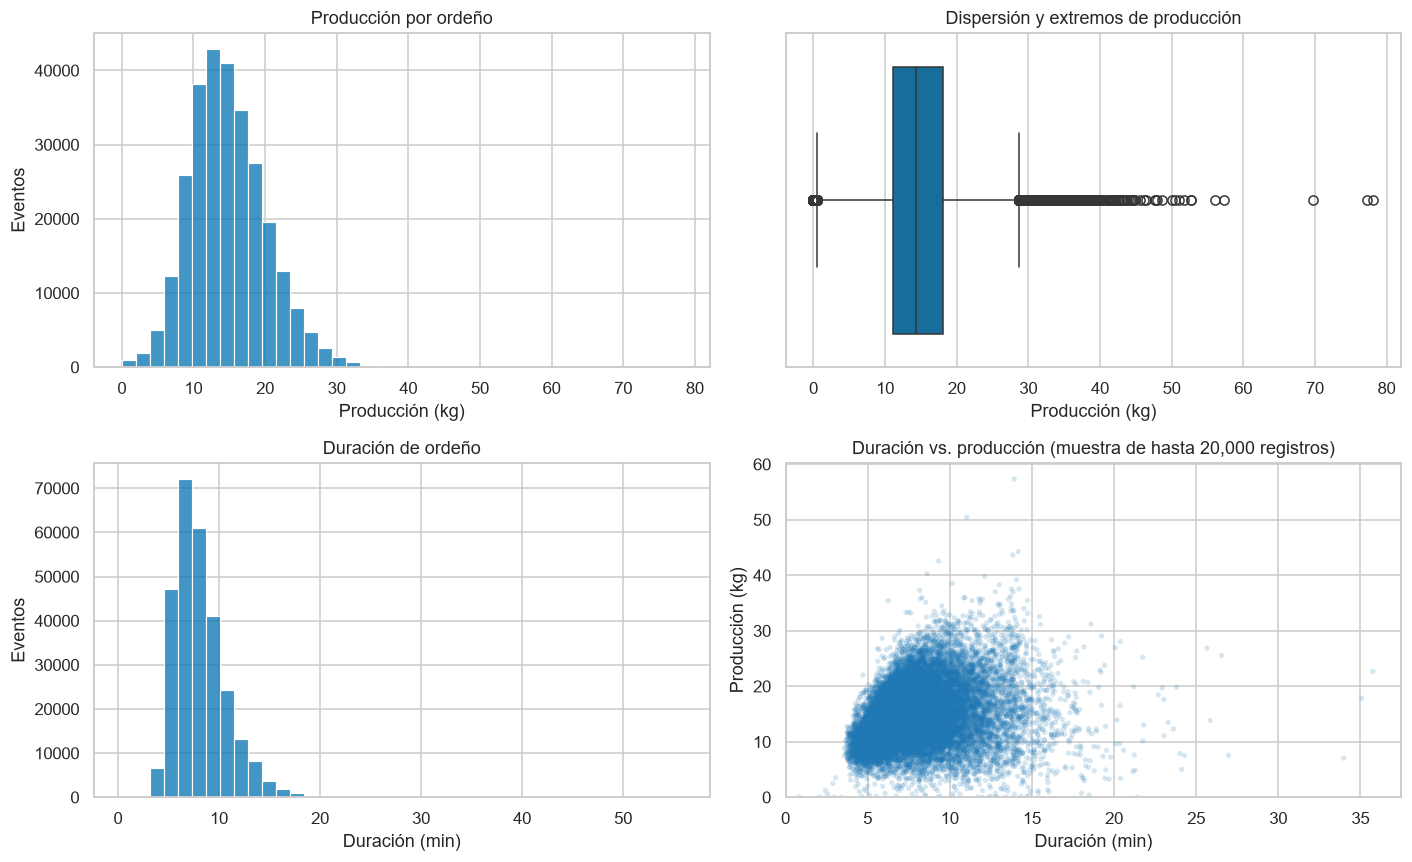

,variable,n,limite_inferior,limite_superior,extremos,extremos_pct,observacion
0,main_produccion_kg,280699,0.525,28.645,3849,1.371,Revisión exploratoria
1,duracion_min,280699,1.525,14.125,7683,2.737,Revisión exploratoria
2,sangre_ppm_di,275473,0.000,0.000,7431,2.698,IQR = 0: regla poco informativa
3,sangre_ppm_dd,273424,0.000,0.000,6544,2.393,IQR = 0: regla poco informativa
4,sangre_ppm_ti,276195,0.000,0.000,3950,1.430,IQR = 0: regla poco informativa
5,sangre_ppm_td,269699,0.000,0.000,3058,1.134,IQR = 0: regla poco informativa


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(data=ordenos, x="main_produccion_kg", bins=40, ax=axes[0, 0])
axes[0, 0].set(title="Producción por ordeño", xlabel="Producción (kg)", ylabel="Eventos")
sns.boxplot(data=ordenos, x="main_produccion_kg", ax=axes[0, 1])
axes[0, 1].set(title="Dispersión y extremos de producción", xlabel="Producción (kg)")
sns.histplot(data=ordenos, x="duracion_min", bins=40, ax=axes[1, 0])
axes[1, 0].set(title="Duración de ordeño", xlabel="Duración (min)", ylabel="Eventos")
muestra_dispersion = ordenos.sample(min(20000, len(ordenos)), random_state=42)
axes[1, 1].scatter(muestra_dispersion.duracion_min, muestra_dispersion.main_produccion_kg,
                   s=12, alpha=0.18, color="tab:blue", edgecolors="none")
axes[1, 1].set(title="Duración vs. producción (muestra de hasta 20,000 registros)",
               xlabel="Duración (min)", ylabel="Producción (kg)")
axes[1, 1].set(xlim=(0, None), ylim=(0, None))
plt.tight_layout()
plt.show()

filas_iqr = []
for c in ["main_produccion_kg", "duracion_min"] + [f"sangre_ppm_{q}" for q in cuartos]:
    s = ordenos[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    extremos = (s.lt(inferior) | s.gt(superior)).sum()
    filas_iqr.append([c, len(s), inferior, superior, extremos, extremos / len(s) * 100,
                      "IQR = 0: regla poco informativa" if iqr == 0 else "Revisión exploratoria"])
display(pd.DataFrame(filas_iqr, columns=["variable", "n", "limite_inferior", "limite_superior",
                                        "extremos", "extremos_pct", "observacion"]))

In [11]:
cuantiles = ordenos[["main_produccion_kg", "duracion_min"]].quantile([0.25, 0.5, 0.75, 0.99])
display(cuantiles)
display(Markdown(
    f"La producción mediana es **{ordenos.main_produccion_kg.median():.2f} kg** y la duración "
    f"mediana **{ordenos.duracion_min.median():.2f} minutos**. El máximo de producción es "
    f"{ordenos.main_produccion_kg.max():.2f} kg. Las distribuciones e IQR usan todos los registros; "
    "solo la dispersión utiliza una muestra reproducible para mantener legible la figura."))


,main_produccion_kg,duracion_min
0.250,11.070,6.250
0.500,14.290,7.600
0.750,18.100,9.400
0.990,29.270,16.067


La producción mediana es **14.29 kg** y la duración mediana **7.60 minutos**. El máximo de producción es 78.17 kg. Las distribuciones e IQR usan todos los registros; solo la dispersión utiliza una muestra reproducible para mantener legible la figura.

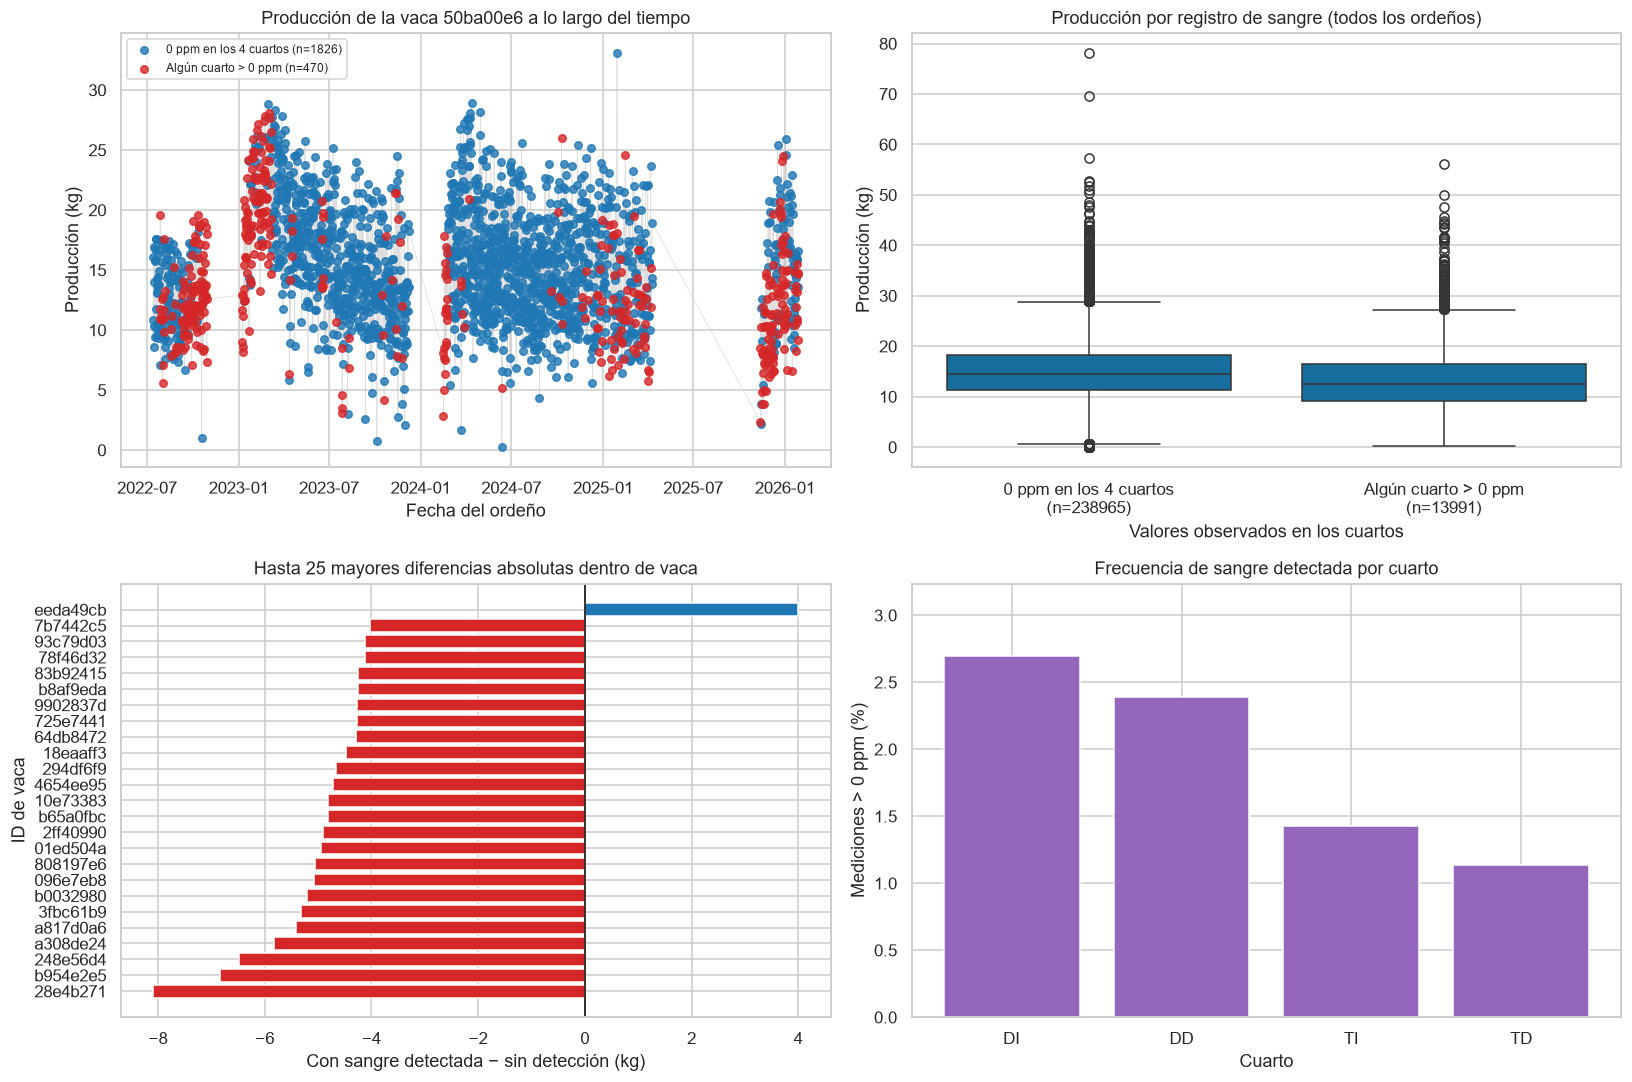

Comparación de 252,956 ordeños con cuatro mediciones; 27,743 excluidos por mediciones faltantes.
Comparación dentro de vaca: 186 vacas con al menos 5 ordeños con detección y 20 sin detección.
Las diferencias son descriptivas: un valor > 0 ppm es una medición del sensor, no un diagnóstico ni prueba de causalidad.


In [12]:
# Para comparar grupos, usamos solo ordeños con mediciones en los cuatro cuartos.
columnas_sangre = [f"sangre_ppm_{q}" for q in cuartos]
sangre = ordenos.loc[ordenos[columnas_sangre].notna().all(axis=1)].copy()
sangre["sangre_detectada"] = sangre[columnas_sangre].gt(0).any(axis=1)
sangre["grupo_sangre"] = sangre["sangre_detectada"].map({False: "0 ppm en los 4 cuartos", True: "Algún cuarto > 0 ppm"})
conteos_sangre = sangre["grupo_sangre"].value_counts()

# Elegimos la vaca con más ordeños con sangre detectada y al menos 20 sin detección.
conteos_vaca = sangre.groupby(["id_vaca", "sangre_detectada"]).size().unstack(fill_value=0).reindex(columns=[False, True], fill_value=0)
vacas_ejemplo = conteos_vaca.loc[conteos_vaca[False].ge(20) & conteos_vaca[True].gt(0)]
id_ejemplo = (vacas_ejemplo[True].idxmax() if not vacas_ejemplo.empty
              else sangre.id_vaca.value_counts().index[0])
serie_vaca = sangre.loc[sangre.id_vaca.eq(id_ejemplo)].sort_values("fecha_hora")

# Diferencia de producción media entre ambos tipos de ordeño, dentro de cada vaca.
medias_vaca = sangre.groupby(["id_vaca", "sangre_detectada"])["main_produccion_kg"].agg(["mean", "size"]).unstack()
vacas_comparables = medias_vaca.loc[(medias_vaca[("size", True)] >= 5) & (medias_vaca[("size", False)] >= 20)]
diferencia_vaca = (vacas_comparables[("mean", True)] - vacas_comparables[("mean", False)]).sort_values()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
ax = axes[0, 0]
ax.plot(serie_vaca.fecha_hora, serie_vaca.main_produccion_kg, color="0.75", linewidth=0.5, alpha=0.5)
for detectada, color, etiqueta in [(False, "tab:blue", "0 ppm en los 4 cuartos"),
                                    (True, "tab:red", "Algún cuarto > 0 ppm")]:
    puntos = serie_vaca.loc[serie_vaca.sangre_detectada.eq(detectada)]
    ax.scatter(puntos.fecha_hora, puntos.main_produccion_kg, s=24, alpha=0.8,
               color=color, label=f"{etiqueta} (n={len(puntos)})", zorder=3)
ax.set(title=f"Producción de la vaca {id_ejemplo} a lo largo del tiempo",
       xlabel="Fecha del ordeño", ylabel="Producción (kg)")
ax.legend(fontsize=8)

ax = axes[0, 1]
orden_grupos = ["0 ppm en los 4 cuartos", "Algún cuarto > 0 ppm"]
sns.boxplot(data=sangre, x="grupo_sangre", y="main_produccion_kg",
            order=orden_grupos, ax=ax)
ax.set(title="Producción por registro de sangre (todos los ordeños)",
       xlabel="Valores observados en los cuartos", ylabel="Producción (kg)")
ax.set_xticks(range(2), [f"{g}\n(n={conteos_sangre[g]})" for g in orden_grupos])

ax = axes[1, 0]
diferencias_grafica = diferencia_vaca.loc[diferencia_vaca.abs().nlargest(25).index].sort_values()
ax.barh(diferencias_grafica.index, diferencias_grafica.values,
        color=["tab:red" if v < 0 else "tab:blue" for v in diferencias_grafica.values])
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Hasta 25 mayores diferencias absolutas dentro de vaca",
       xlabel="Con sangre detectada − sin detección (kg)", ylabel="ID de vaca")

ax = axes[1, 1]
tasas_cuarto = ordenos[columnas_sangre].gt(0).sum().div(ordenos[columnas_sangre].notna().sum()).mul(100)
ax.bar([q.upper() for q in cuartos], tasas_cuarto.values, color="tab:purple")
ax.set(title="Frecuencia de sangre detectada por cuarto",
       xlabel="Cuarto", ylabel="Mediciones > 0 ppm (%)", ylim=(0, tasas_cuarto.max() * 1.2))
plt.tight_layout()
plt.show()
print(f"Comparación de {len(sangre):,} ordeños con cuatro mediciones; {len(ordenos) - len(sangre):,} excluidos por mediciones faltantes.")
print(f"Comparación dentro de vaca: {len(diferencia_vaca)} vacas con al menos 5 ordeños con detección y 20 sin detección.")
print("Las diferencias son descriptivas: un valor > 0 ppm es una medición del sensor, no un diagnóstico ni prueba de causalidad.")

In [13]:
resumen_sangre = sangre.groupby("grupo_sangre").agg(
    registros=("id_vaca", "size"), vacas=("id_vaca", "nunique"),
    media_kg=("main_produccion_kg", "mean"), mediana_kg=("main_produccion_kg", "median"))
display(resumen_sangre)
display(Markdown(
    f"Con cuatro mediciones disponibles, **{sangre.sangre_detectada.mean():.2%}** de los registros "
    f"tienen algún valor > 0 ppm. Entre las {len(diferencia_vaca)} vacas comparables, "
    f"{diferencia_vaca.lt(0).sum()} presentan menor producción media con detección y "
    f"{diferencia_vaca.gt(0).sum()} mayor. La gráfica muestra hasta 25 diferencias extremas; "
    "la serie `diferencia_vaca` conserva todas. Comparar dentro de vaca reduce diferencias "
    "entre animales, pero no controla etapa de lactancia, intervalo ni periodo."))


,registros,vacas,media_kg,mediana_kg
grupo_sangre,,,,
0 ppm en los 4 cuartos,238965,200,15.008,14.460
Algún cuarto > 0 ppm,13991,198,13.083,12.420


Con cuatro mediciones disponibles, **5.53%** de los registros tienen algún valor > 0 ppm. Entre las 186 vacas comparables, 154 presentan menor producción media con detección y 32 mayor. La gráfica muestra hasta 25 diferencias extremas; la serie `diferencia_vaca` conserva todas. Comparar dentro de vaca reduce diferencias entre animales, pero no controla etapa de lactancia, intervalo ni periodo.

## 4. Cobertura temporal y diferencias entre vacas

Los totales diarios dependen tanto de la producción por evento como de la cantidad de vacas y ordeños observados. Los días sin registros se muestran como huecos.

,count,mean,std,min,25%,50%,75%,max
produccion_total_kg,"1,296.000","3,209.185","1,406.229",767.270,"1,997.867","3,224.690","4,461.430","6,696.360"
produccion_media_kg,"1,296.000",14.805,0.984,11.742,14.146,14.752,15.395,19.057
ordenos,"1,296.000",216.589,93.176,52.000,135.000,217.000,294.250,422.000
vacas,"1,296.000",89.538,37.642,25.000,58.000,87.000,126.000,175.000


Días sin eventos en el CSV: 0
Días sin ordeños: 0


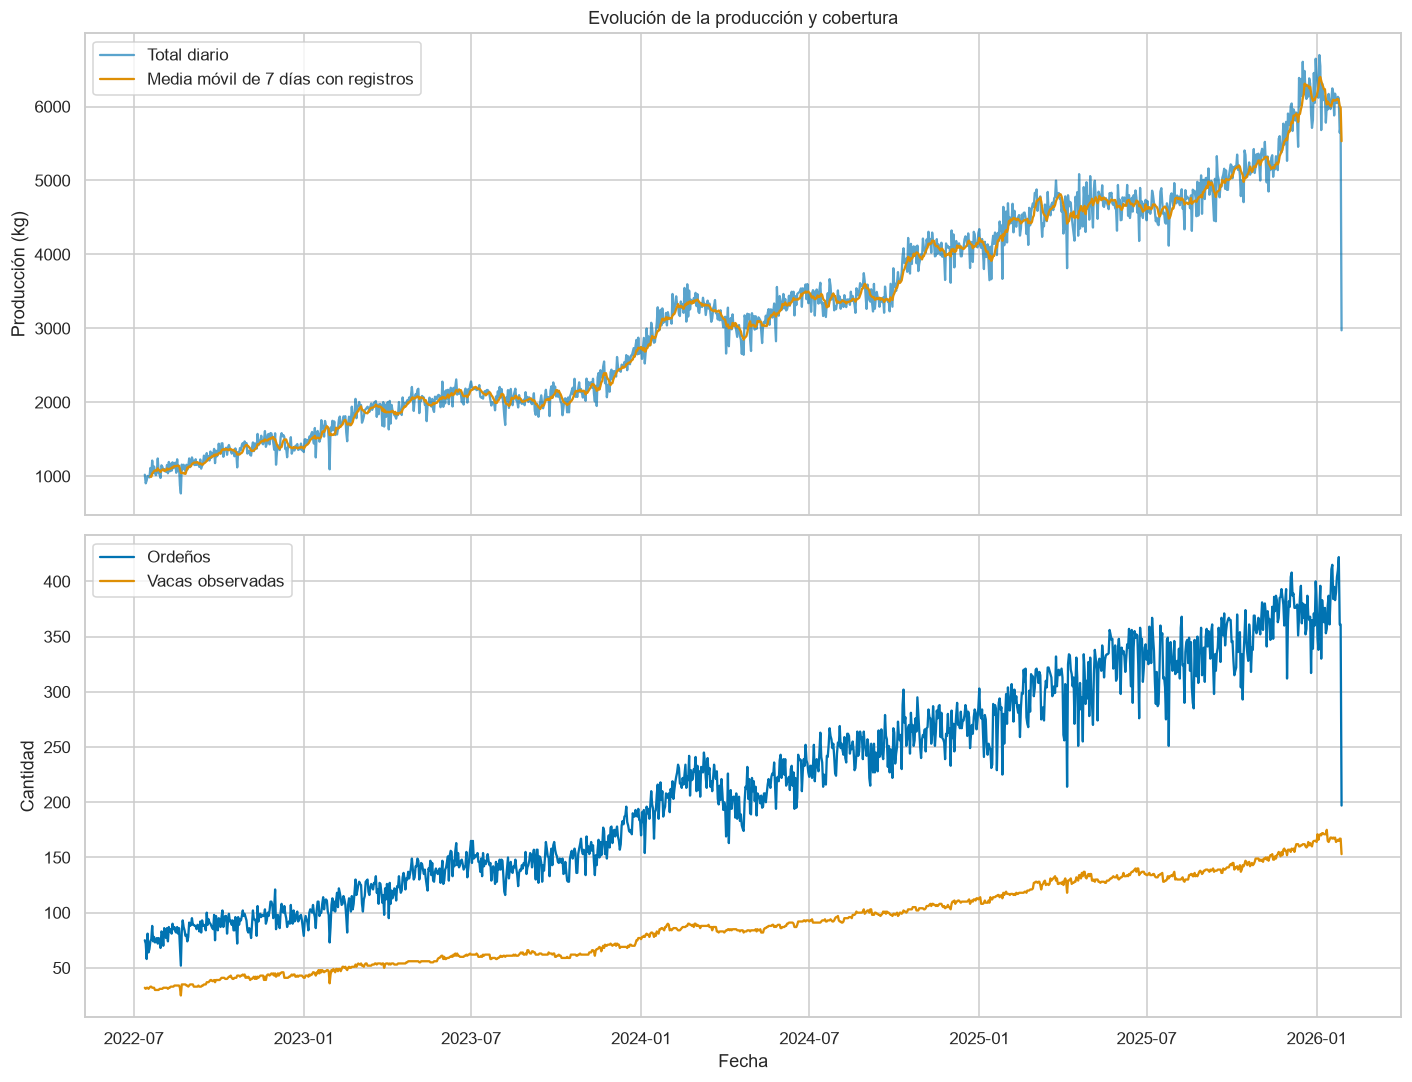

In [14]:
diario = ordenos.dropna(subset=["fecha"]).groupby("fecha").agg(
    produccion_total_kg=("main_produccion_kg", lambda s: s.sum(min_count=1)),
    produccion_media_kg=("main_produccion_kg", "mean"),
    ordenos=("id_vaca", "size"), vacas=("id_vaca", "nunique"))

calendario = pd.date_range(df.fecha.min(), df.fecha.max(), freq="D")
diario = diario.reindex(calendario)
diario.index.name = "fecha"
display(diario.describe().T)
print(f"Días sin eventos en el CSV: {len(calendario.difference(df.fecha.dropna().unique()))}")
print(f"Días sin ordeños: {diario.ordenos.isna().sum()}")

fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)
axes[0].plot(diario.index, diario.produccion_total_kg, alpha=0.65, label="Total diario")
axes[0].plot(diario.index, diario.produccion_total_kg.rolling(7, min_periods=7).mean(),
             label="Media móvil de 7 días con registros")
axes[0].set(ylabel="Producción (kg)", title="Evolución de la producción y cobertura")
axes[0].legend()
axes[1].plot(diario.index, diario.ordenos, label="Ordeños")
axes[1].plot(diario.index, diario.vacas, label="Vacas observadas")
axes[1].set(ylabel="Cantidad", xlabel="Fecha")
axes[1].legend()
plt.tight_layout()
plt.show()


La producción total diaria cambia cuando varían la cantidad de vacas observadas,
los registros por vaca o la producción por registro. Un día con registros no
garantiza cobertura completa. La ventana móvil exige siete días con datos;
los huecos se conservan. Más abajo se comparan estas cantidades por mes para
separar cambios de cobertura de cambios en la media.


,ordenos,dias,media_kg,mediana_kg,total_kg,duracion_media_min
id_vaca,,,,,,
b0032980,97,60,19.878,20.530,"1,928.150",8.341
080047a3,2683,1127,19.500,18.950,"52,318.370",7.304
45d45b48,2576,1086,19.289,18.650,"49,687.680",10.223
a3a44250,275,115,18.846,18.980,"5,182.630",7.935
725e7441,1836,817,18.798,18.535,"34,512.590",8.248
...,...,...,...,...,...,...
753457c4,1121,428,10.077,9.980,"11,295.910",7.685
c81114be,11,10,9.464,9.720,104.100,9.703
b3f94fd9,2,2,7.860,7.860,15.720,13.067


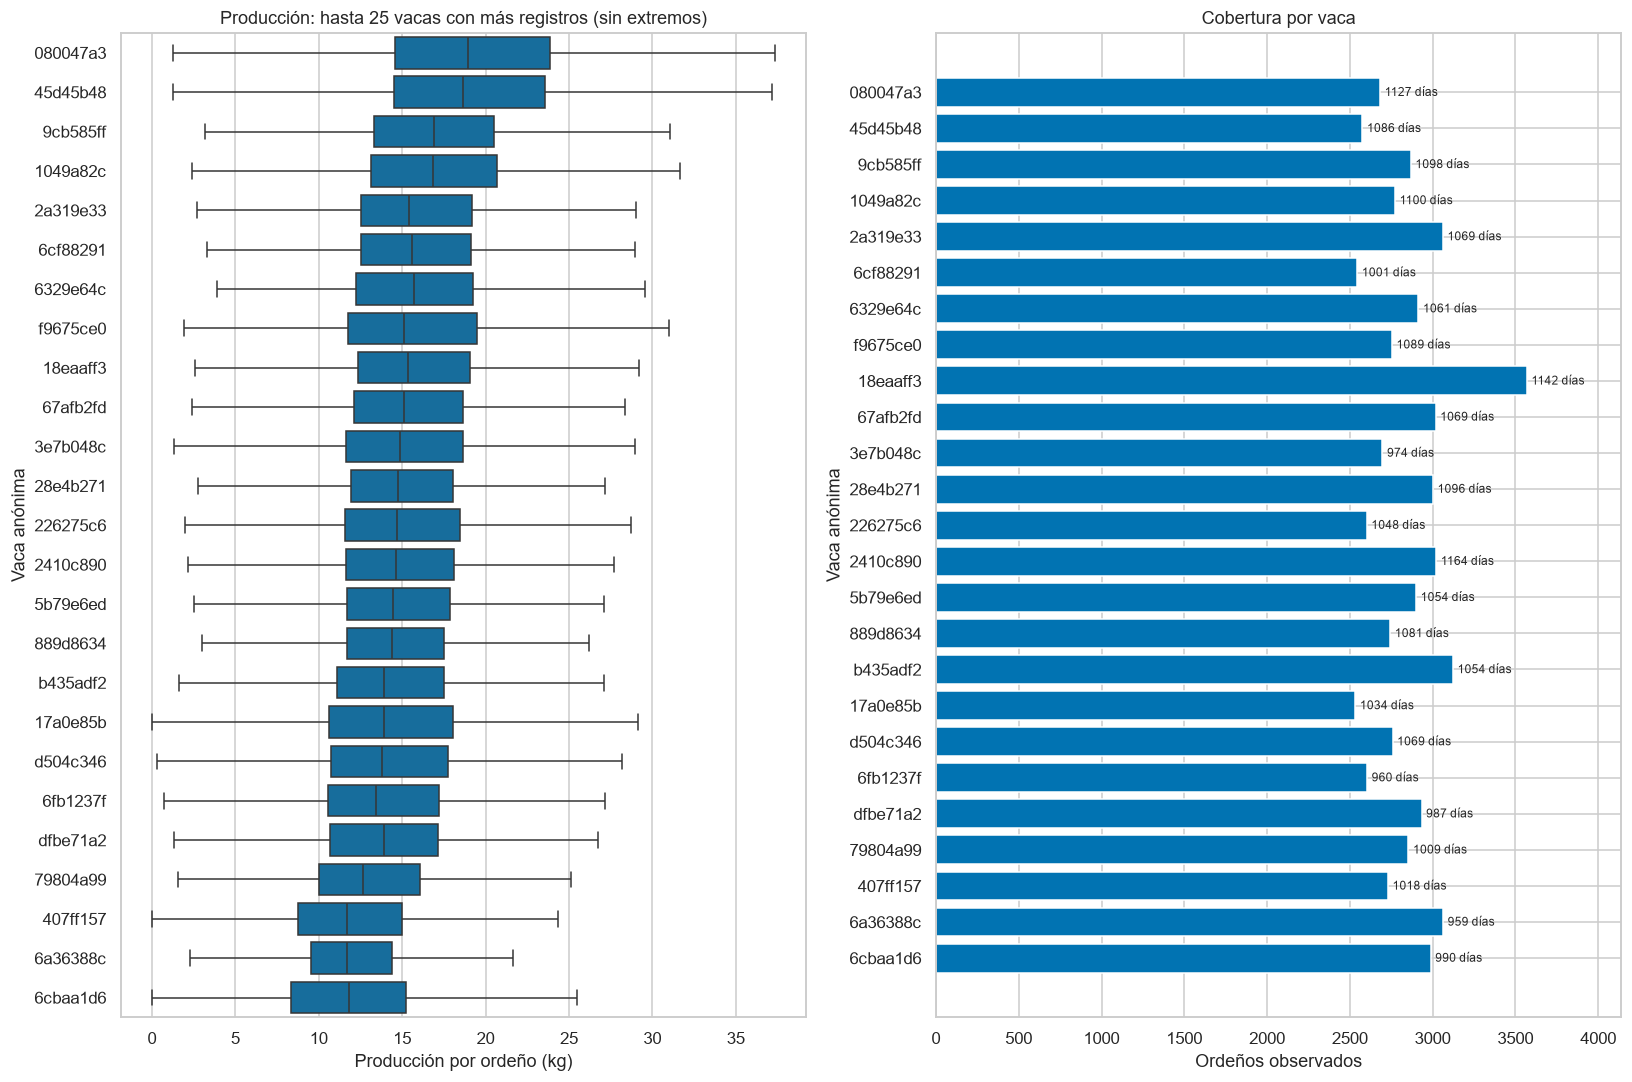

In [15]:
## Número de ordeños, días, producción media y mediana, producción total y duración media por vaca
por_vaca = ordenos.groupby("id_vaca").agg(
    ordenos=("main_produccion_kg", "count"), dias=("fecha", "nunique"),
    media_kg=("main_produccion_kg", "mean"), mediana_kg=("main_produccion_kg", "median"),
    total_kg=("main_produccion_kg", "sum"), duracion_media_min=("duracion_min", "mean"))
por_vaca = por_vaca.sort_values("media_kg", ascending=False)
display(por_vaca)
# Hasta 25 vacas con más registros, ordenadas por su media; la tabla conserva todas.
vacas_grafica = por_vaca.nlargest(25, "ordenos").sort_values("media_kg", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 10))
sns.boxplot(data=ordenos.loc[ordenos.id_vaca.isin(vacas_grafica.index)], y="id_vaca", x="main_produccion_kg",
            order=vacas_grafica.index, showfliers=False, ax=axes[0])
axes[0].set(title="Producción: hasta 25 vacas con más registros (sin extremos)",
            xlabel="Producción por ordeño (kg)", ylabel="Vaca anónima")
barras_cobertura = axes[1].barh(vacas_grafica.index, vacas_grafica.ordenos)
axes[1].bar_label(barras_cobertura, labels=[f"{dias} días" for dias in vacas_grafica.dias],
                  padding=3, fontsize=8)
axes[1].invert_yaxis()
axes[1].set(title="Cobertura por vaca", xlabel="Ordeños observados", ylabel="Vaca anónima",
            xlim=(0, por_vaca.ordenos.max() * 1.16))
plt.tight_layout()
plt.show()

La tabla incluye todas las vacas. Para que las etiquetas sean legibles, las
gráficas muestran hasta 25 con mayor cantidad de registros. La comparación de
medias debe acompañarse del número de registros y días disponibles: una vaca
observada pocos días puede no ser comparable con otra seguida durante años.
El conteo acumulado de registros no es la frecuencia diaria de ordeño.


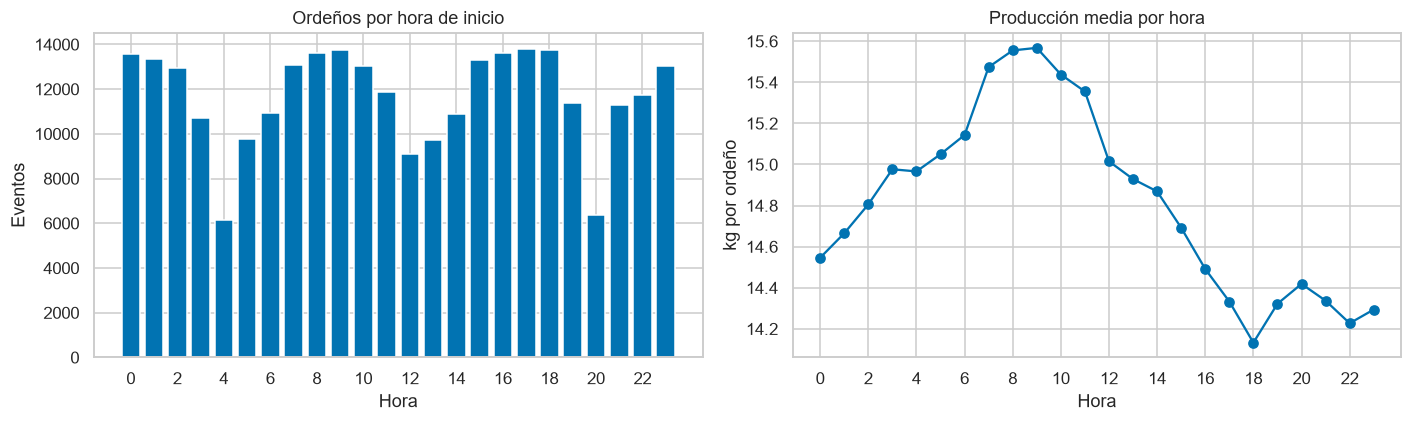

,eventos,vacas,dias,media_kg,mediana_kg
mes,,,,,
2022-07,1406,34,19,14.161,13.470
2022-08,2530,37,31,13.530,12.950
2022-09,2667,42,30,13.791,13.300
2022-10,2867,46,31,14.713,14.170
2022-11,2855,48,30,15.192,14.640
2022-12,2979,49,31,14.645,14.070
2023-01,3075,52,31,15.543,14.830
2023-02,3081,55,28,15.836,15.440
2023-03,3716,56,31,15.884,15.590


,eventos,vacas,media_kg
misc_eo_po,,,
64ddd637,97643,173,14.692
a335a133,2,2,0.000
ab18abfc,91649,142,15.502
ff24d34e,91405,207,14.263


In [16]:
por_hora = ordenos.groupby("hora").agg(eventos=("id_vaca", "size"),
    media_kg=("main_produccion_kg", "mean")).reindex(range(24))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(por_hora.index, por_hora.eventos)
axes[0].set(title="Ordeños por hora de inicio", xlabel="Hora", ylabel="Eventos", xticks=range(0, 24, 2))
axes[1].plot(por_hora.index, por_hora.media_kg, marker="o")
axes[1].set(title="Producción media por hora", xlabel="Hora", ylabel="kg por ordeño", xticks=range(0, 24, 2))
plt.tight_layout()
plt.show()

mensual = ordenos.groupby("mes").agg(eventos=("id_vaca", "size"),
    vacas=("id_vaca", "nunique"), dias=("fecha", "nunique"),
    media_kg=("main_produccion_kg", "mean"), mediana_kg=("main_produccion_kg", "median"))
display(mensual)
display(ordenos.groupby("misc_eo_po", dropna=False).agg(eventos=("id_vaca", "size"),
    vacas=("id_vaca", "nunique"), media_kg=("main_produccion_kg", "mean")))

In [17]:
horas_bajas = por_hora.eventos.nsmallest(3)
display(Markdown(
    f"Las tres horas con menos registros acumulados son "
    f"**{', '.join(f'{int(h):02d}:00' for h in horas_bajas.index)}**. "
    f"La mayor producción media por registro aparece a las **{int(por_hora.media_kg.idxmax()):02d}:00**. "
    "Son asociaciones descriptivas; pueden depender de rutinas del equipo, composición de vacas "
    "y tiempo desde el registro previo. Los códigos de equipo no se interpretan automáticamente "
    "como máquinas distintas sin validar la correspondencia original."))


Las tres horas con menos registros acumulados son **04:00, 20:00, 12:00**. La mayor producción media por registro aparece a las **09:00**. Son asociaciones descriptivas; pueden depender de rutinas del equipo, composición de vacas y tiempo desde el registro previo. Los códigos de equipo no se interpretan automáticamente como máquinas distintas sin validar la correspondencia original.

,eventos,vacas,dias,media_kg,mediana_kg,kg_por_vaca_dia_observado,registros_por_vaca_dia_observado,produccion_total_kg,dias_calendario,cobertura_dias_pct,porcentaje_accion_no_informada,vacas_evaluables_sangre,vacas_con_deteccion,vacas_con_deteccion_pct
2022-07,1406,34,19,14.161,13.470,33.463,2.363,"19,910.410",31,61.290,100.000,30,13,43.333
2022-08,2530,37,31,13.530,12.950,33.429,2.471,"34,230.890",31,100.000,100.000,33,14,42.424
2022-09,2667,42,30,13.791,13.300,34.311,2.488,"36,781.640",30,100.000,100.000,38,13,34.211
2022-10,2867,46,31,14.713,14.170,32.827,2.231,"42,182.650",31,100.000,100.000,43,14,32.558
2022-11,2855,48,30,15.192,14.640,34.424,2.266,"43,373.720",30,100.000,100.000,44,26,59.091
2022-12,2979,49,31,14.645,14.070,32.656,2.230,"43,627.910",31,100.000,100.000,44,13,29.545
2023-01,3075,52,31,15.543,14.830,34.336,2.209,"47,795.620",31,100.000,100.000,48,29,60.417
2023-02,3081,55,28,15.836,15.440,35.077,2.215,"48,791.480",28,100.000,100.000,50,27,54.000
2023-03,3716,56,31,15.884,15.590,35.904,2.260,"59,026.530",31,100.000,100.000,51,26,50.980
2023-04,3764,58,30,15.434,14.970,35.641,2.309,"58,094.990",30,100.000,100.000,53,23,43.396


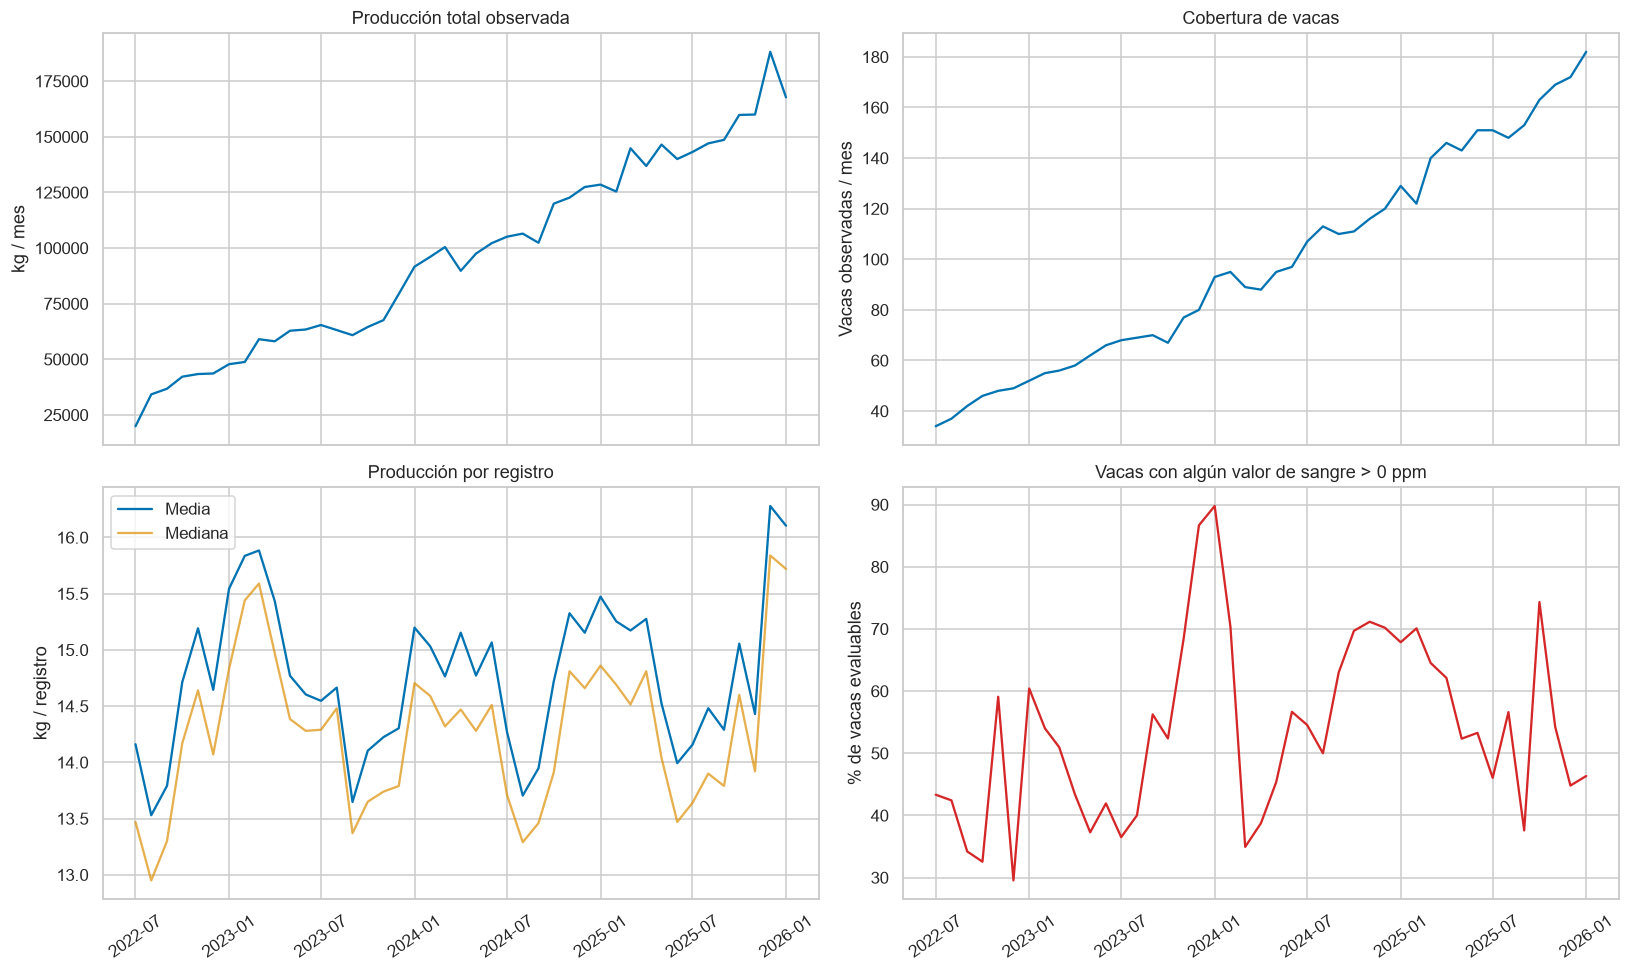

Vaca-día observado: no equivale a producción completa de 24 horas; puede tener registros faltantes.
La probabilidad de detectar al menos un valor > 0 aumenta con el número de registros por vaca.


In [18]:
# Calendario mensual completo: los meses sin registros quedan como NaN.
meses = pd.period_range(ordenos.mes.min(), ordenos.mes.max(), freq="M")
mensual = mensual.reindex(meses)
vaca_dia = ordenos.dropna(subset=["fecha"]).groupby(["fecha", "id_vaca"]).agg(
    kg=("main_produccion_kg", lambda s: s.sum(min_count=1)), registros=("id_vaca", "size"))
vaca_dia["mes"] = vaca_dia.index.get_level_values("fecha").to_period("M")
mensual["kg_por_vaca_dia_observado"] = vaca_dia.groupby("mes").kg.mean()
mensual["registros_por_vaca_dia_observado"] = vaca_dia.groupby("mes").registros.mean()
mensual["produccion_total_kg"] = ordenos.groupby("mes").main_produccion_kg.sum(min_count=1)
mensual["dias_calendario"] = mensual.index.days_in_month
mensual["cobertura_dias_pct"] = mensual.dias.div(mensual.dias_calendario).mul(100)
mensual["porcentaje_accion_no_informada"] = ordenos.groupby("mes").criterio_inclusion.agg(
    lambda s: s.eq("Producción con acción no informada").mean() * 100)
mensual["vacas_evaluables_sangre"] = sangre.groupby("mes").id_vaca.nunique()
mensual["vacas_con_deteccion"] = (sangre.loc[sangre.sangre_detectada]
    .groupby("mes").id_vaca.nunique().reindex(meses, fill_value=0))
mensual["vacas_con_deteccion_pct"] = mensual.vacas_con_deteccion.div(mensual.vacas_evaluables_sangre).mul(100)
display(mensual)

x = mensual.index.to_timestamp()
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
axes[0, 0].plot(x, mensual.produccion_total_kg)
axes[0, 0].set(title="Producción total observada", ylabel="kg / mes")
axes[0, 1].plot(x, mensual.vacas)
axes[0, 1].set(title="Cobertura de vacas", ylabel="Vacas observadas / mes")
axes[1, 0].plot(x, mensual.media_kg, label="Media")
axes[1, 0].plot(x, mensual.mediana_kg, label="Mediana", alpha=0.7)
axes[1, 0].set(title="Producción por registro", ylabel="kg / registro")
axes[1, 0].legend()
axes[1, 1].plot(x, mensual.vacas_con_deteccion_pct, color="tab:red")
axes[1, 1].set(title="Vacas con algún valor de sangre > 0 ppm", ylabel="% de vacas evaluables")
for ax in axes.flat:
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()
print("Vaca-día observado: no equivale a producción completa de 24 horas; puede tener registros faltantes.")
print("La probabilidad de detectar al menos un valor > 0 aumenta con el número de registros por vaca.")


In [19]:
periodos_parciales = mensual.index[mensual.dias.lt(mensual.dias_calendario)].astype(str).tolist()
display(Markdown(
    f"Hay **{mensual.eventos.notna().sum()} meses con registros**. Los meses con menos días "
    f"observados que días calendario son: **{', '.join(periodos_parciales) or 'ninguno'}**. "
    f"El número de vacas por mes va de {mensual.vacas.min():.0f} a {mensual.vacas.max():.0f}, "
    f"mientras la producción media por registro va de {mensual.media_kg.min():.2f} a "
    f"{mensual.media_kg.max():.2f} kg. El crecimiento del total debe interpretarse junto con "
    "esta expansión de cobertura. Tener varios años permite explorar recurrencias, pero "
    "no demuestra estacionalidad sin controlar cambios de vacas, lactancia y exportación."))


Hay **43 meses con registros**. Los meses con menos días observados que días calendario son: **2022-07, 2026-01**. El número de vacas por mes va de 34 a 182, mientras la producción media por registro va de 13.53 a 16.28 kg. El crecimiento del total debe interpretarse junto con esta expansión de cobertura. Tener varios años permite explorar recurrencias, pero no demuestra estacionalidad sin controlar cambios de vacas, lactancia y exportación.

## 5. Correlaciones exploratorias

Se usa Spearman para describir asociaciones monotónicas. Cada coeficiente utiliza pares disponibles; por eso se muestra también su tamaño de muestra. Se excluyen identificadores y columnas completamente vacías. Las medidas por cuarto que componen la producción total pueden correlacionarse por construcción.

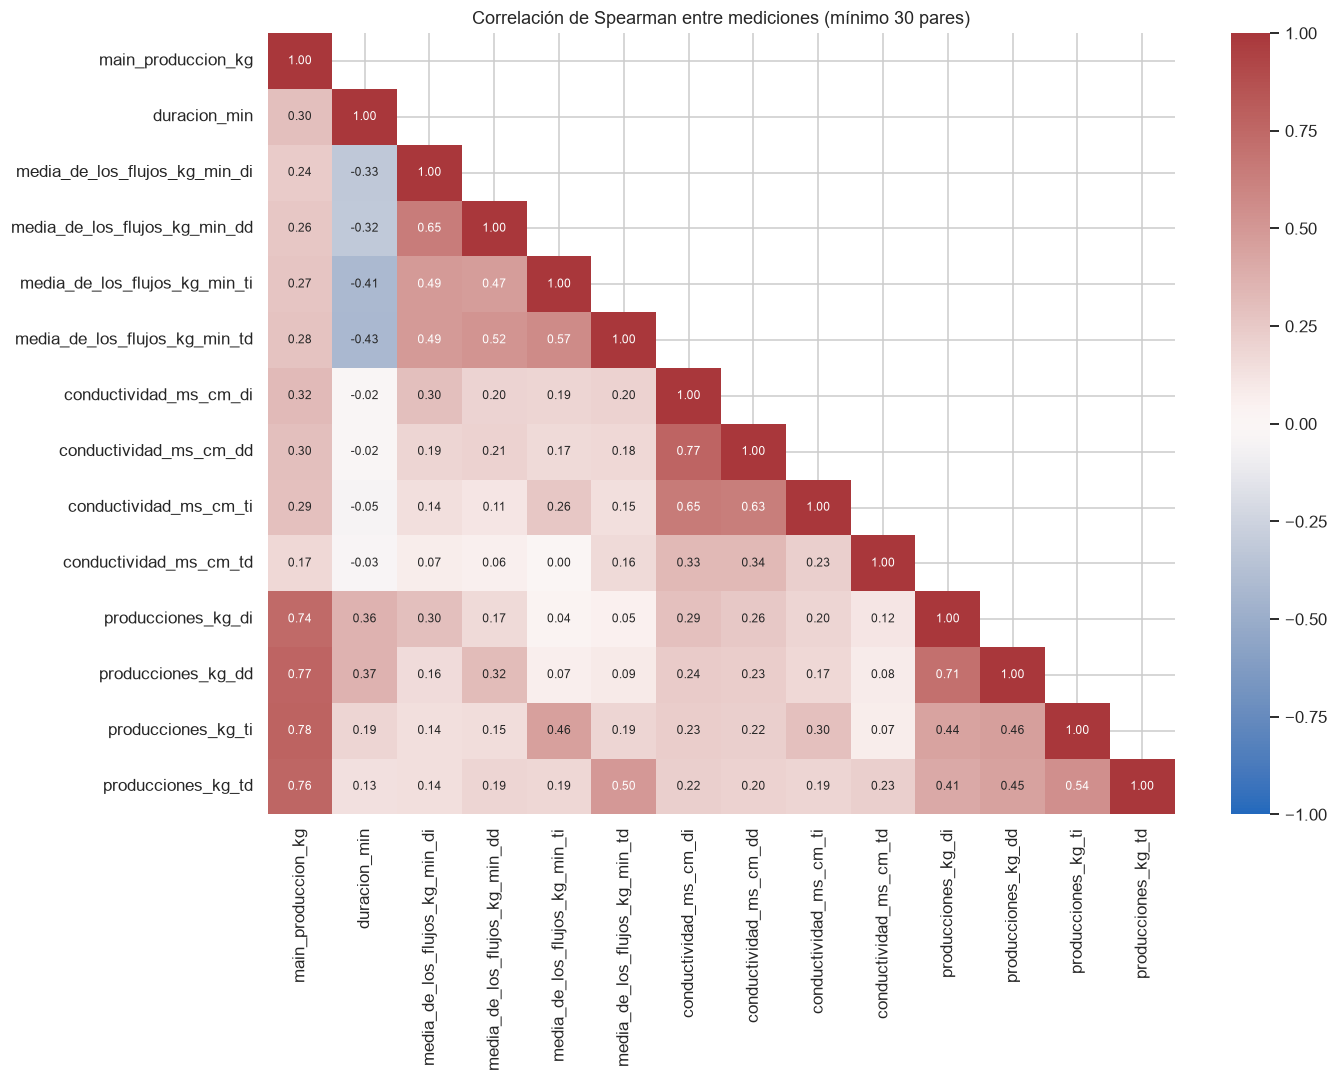

,spearman_con_produccion,pares_disponibles
producciones_kg_ti,0.777,276195
producciones_kg_dd,0.769,273424
producciones_kg_td,0.758,269699
producciones_kg_di,0.741,275473
conductividad_ms_cm_di,0.320,275473
duracion_min,0.304,280699
conductividad_ms_cm_dd,0.299,273424
conductividad_ms_cm_ti,0.294,276195
media_de_los_flujos_kg_min_td,0.277,269699
media_de_los_flujos_kg_min_ti,0.268,276195


In [20]:
variables = ["main_produccion_kg", "duracion_min"] + [f"media_de_los_flujos_kg_min_{q}" for q in cuartos] + [
    f"conductividad_ms_cm_{q}" for q in cuartos] + [f"producciones_kg_{q}" for q in cuartos]
correlacion = ordenos[variables].corr(method="spearman", min_periods=30)
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(correlacion, mask=np.triu(np.ones_like(correlacion, dtype=bool), k=1),
            cmap="vlag", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", ax=ax,
            annot_kws={"fontsize": 8})
ax.set_title("Correlación de Spearman entre mediciones (mínimo 30 pares)")
plt.tight_layout()
plt.show()
asociaciones = pd.DataFrame({
    "spearman_con_produccion": correlacion["main_produccion_kg"].drop("main_produccion_kg"),
    "pares_disponibles": {c: ordenos[["main_produccion_kg", c]].dropna().shape[0]
                         for c in variables if c != "main_produccion_kg"},
}).sort_values("spearman_con_produccion", key=lambda s: s.abs(), ascending=False)
display(asociaciones)

In [21]:
display(Markdown(
    f"La duración tiene una correlación de Spearman de "
    f"**{correlacion.loc['duracion_min', 'main_produccion_kg']:.3f}** con la producción. "
    "Las producciones por cuarto forman parte del total: su correlación es en parte una "
    "relación de composición y usarlas para predecir el total del mismo registro generaría "
    "una evaluación circular. Las asociaciones de sensores pueden mezclar diferencias entre "
    "vacas, periodos y equipos; no se interpretan como efectos causales."))


La duración tiene una correlación de Spearman de **0.304** con la producción. Las producciones por cuarto forman parte del total: su correlación es en parte una relación de composición y usarlas para predecir el total del mismo registro generaría una evaluación circular. Las asociaciones de sensores pueden mezclar diferencias entre vacas, periodos y equipos; no se interpretan como efectos causales.

## 6. Nuevo: intervalo entre registros y producción

Se distinguen el intervalo declarado por el equipo, el tiempo entre **inicios**
consecutivos observados de una vaca y el tiempo desde el **fin del registro previo**
(inicio previo + duración). La comparación permite investigar qué referencia
temporal usa el campo del equipo. La secuencia observada puede atravesar huecos
de cobertura; no garantiza que los ordeños sean realmente consecutivos.

La asociación con producción usa el intervalo **declarado**, entre 0 y 24 horas.
Los ceros, ausentes y valores mayores a 24 horas se reportan aparte. Esta
restricción exploratoria no elimina registros de la base general.

,intervalo_declarado_h,intervalo_observado_h,intervalo_desde_fin_previo_h
disponibles,"278,968.000","280,492.000","280,492.000"
cero,403.000,0.000,0.000
mayores_24_h,"2,522.000","2,864.000","2,768.000"
mediana_h,9.072,9.214,9.081
percentil_99_h,23.568,24.095,23.940
maximo_h,"2,956.367","6,550.317","6,550.184"


,referencia,pares,error_mediano_min,coinciden_hasta_1_segundo_pct
0,Entre inicios,278767,7.600,0.000
1,Desde fin previo,278767,0.000,99.911


El intervalo declarado coincide, con tolerancia de un segundo, con el tiempo desde el **fin del registro previo** en **99.91%** de 278,767 pares comparables. Esto sugiere que el equipo usa esa referencia temporal. La diferencia respecto al tiempo entre inicios se explica principalmente por la duración del registro anterior. Los casos restantes requieren revisar huecos, reinicios de contadores o eventos intermedios.

Pares que no coinciden dentro de un segundo desde el fin previo: 248


,registros,vacas,media_kg,mediana_kg
rango_intervalo,,,,
"(0, 4]",4051,191,7.724,7.840
"(4, 6]",26659,196,10.566,10.520
"(6, 8]",66876,196,12.376,12.160
"(8, 10]",72619,199,14.572,14.290
"(10, 12]",48351,199,16.526,16.240
"(12, 16]",43061,200,18.464,18.320
"(16, 24]",14426,200,20.011,19.880


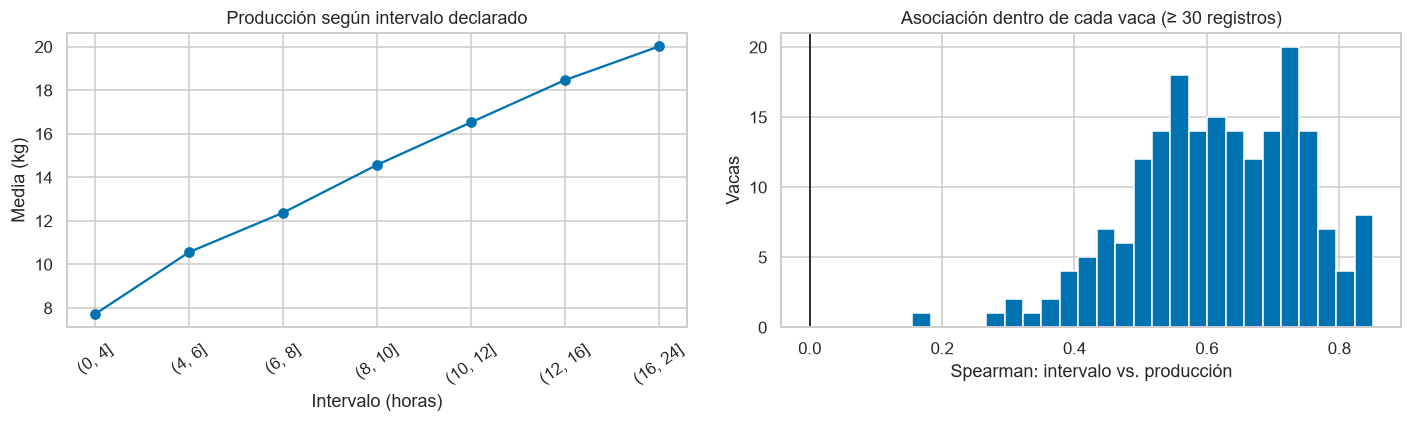

Para intervalos declarados entre 0 y 24 horas, la asociación global con producción es **ρ = 0.544**. En 195 vacas con suficientes registros, la mediana de las correlaciones es **0.624**. Este resultado describe producción por registro; no demuestra que esperar más aumente la producción diaria. Tampoco controla etapa de lactancia ni cambios de manejo.

In [22]:
secuencia = ordenos.dropna(subset=["id_vaca", "fecha_hora"]).sort_values(["id_vaca", "fecha_hora"]).copy()
secuencia["intervalo_observado_h"] = secuencia.groupby("id_vaca").fecha_hora.diff().dt.total_seconds() / 3600
secuencia["duracion_previa_h"] = secuencia.groupby("id_vaca").duracion_min.shift() / 60
secuencia["intervalo_desde_fin_previo_h"] = secuencia.intervalo_observado_h - secuencia.duracion_previa_h
resumen_intervalos = pd.DataFrame({
    c: {"disponibles": secuencia[c].notna().sum(), "cero": secuencia[c].eq(0).sum(),
        "mayores_24_h": secuencia[c].gt(24).sum(), "mediana_h": secuencia[c].median(),
        "percentil_99_h": secuencia[c].quantile(0.99), "maximo_h": secuencia[c].max()}
    for c in ["intervalo_declarado_h", "intervalo_observado_h", "intervalo_desde_fin_previo_h"]})
display(resumen_intervalos)
comparables_intervalo = secuencia[["intervalo_declarado_h", "intervalo_observado_h", "intervalo_desde_fin_previo_h"]].dropna()
error_entre_inicios = comparables_intervalo.intervalo_observado_h.sub(comparables_intervalo.intervalo_declarado_h).abs()
error_desde_fin = comparables_intervalo.intervalo_desde_fin_previo_h.sub(comparables_intervalo.intervalo_declarado_h).abs()
coincide_desde_fin = error_desde_fin.le(1 / 3600 + 1e-9)
display(pd.DataFrame({
    "referencia": ["Entre inicios", "Desde fin previo"],
    "pares": [len(comparables_intervalo)] * 2,
    "error_mediano_min": [error_entre_inicios.median() * 60, error_desde_fin.median() * 60],
    "coinciden_hasta_1_segundo_pct": [error_entre_inicios.le(1 / 3600 + 1e-9).mean() * 100, coincide_desde_fin.mean() * 100],
}))
display(Markdown(
    f"El intervalo declarado coincide, con tolerancia de un segundo, con el tiempo "
    f"desde el **fin del registro previo** en **{coincide_desde_fin.mean():.2%}** "
    f"de {len(comparables_intervalo):,} pares comparables. Esto sugiere que el equipo "
    "usa esa referencia temporal. La diferencia respecto al tiempo entre inicios "
    "se explica principalmente por la duración del registro anterior. Los casos "
    "restantes requieren revisar huecos, reinicios de contadores o eventos intermedios."))
print(f"Pares que no coinciden dentro de un segundo desde el fin previo: {(~coincide_desde_fin).sum():,}")

intervalos = secuencia.loc[secuencia.intervalo_declarado_h.gt(0)
    & secuencia.intervalo_declarado_h.le(24) & secuencia.main_produccion_kg.notna()].copy()
intervalos["rango_intervalo"] = pd.cut(intervalos.intervalo_declarado_h,
    bins=[0, 4, 6, 8, 10, 12, 16, 24])
por_intervalo = intervalos.groupby("rango_intervalo", observed=True).agg(
    registros=("id_vaca", "size"), vacas=("id_vaca", "nunique"),
    media_kg=("main_produccion_kg", "mean"), mediana_kg=("main_produccion_kg", "median"))
display(por_intervalo)

# Una correlación por vaca evita que un solo animal con muchos registros domine el resumen.
correlaciones_intervalo = []
for vaca, grupo in intervalos.groupby("id_vaca"):
    if len(grupo) >= 30 and grupo.intervalo_declarado_h.nunique() > 1 and grupo.main_produccion_kg.nunique() > 1:
        correlaciones_intervalo.append({"id_vaca": vaca, "n": len(grupo),
            "rho": grupo.intervalo_declarado_h.corr(grupo.main_produccion_kg, method="spearman")})
correlaciones_intervalo = pd.DataFrame(correlaciones_intervalo, columns=["id_vaca", "n", "rho"])
rho_intervalo = intervalos.intervalo_declarado_h.corr(intervalos.main_produccion_kg, method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(por_intervalo.index.astype(str), por_intervalo.media_kg, marker="o")
axes[0].set(title="Producción según intervalo declarado", xlabel="Intervalo (horas)", ylabel="Media (kg)")
axes[0].tick_params(axis="x", rotation=35)
axes[1].hist(correlaciones_intervalo.rho.dropna(), bins=25)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set(title="Asociación dentro de cada vaca (≥ 30 registros)", xlabel="Spearman: intervalo vs. producción", ylabel="Vacas")
plt.tight_layout()
plt.show()
display(Markdown(
    f"Para intervalos declarados entre 0 y 24 horas, la asociación global con producción es "
    f"**ρ = {rho_intervalo:.3f}**. En {len(correlaciones_intervalo)} vacas con suficientes registros, "
    f"la mediana de las correlaciones es **{correlaciones_intervalo.rho.median():.3f}**. "
    "Este resultado describe producción por registro; no demuestra que esperar más aumente "
    "la producción diaria. Tampoco controla etapa de lactancia ni cambios de manejo."))


## 7. Nuevo: etiquetas de incidentes por cuarto y cobertura de sensores

Se expanden las etiquetas `DI`, `DD`, `TI`, `TD` y `Todos`. Los porcentajes usan
como denominador todos los registros incluidos y representan **etiquetas
registradas**, no probabilidades clínicas ni ausencia confirmada cuando el campo
está vacío. Se compara también la cobertura de mediciones por cuarto.


,patada,incompleto,pezones_no_encontrados,sangre_positiva_pct_disponibles,produccion_cuarto_ausente_pct
DI,5.790,2.456,2.017,2.698,1.862
DD,3.139,2.318,1.882,2.393,2.592
TI,3.710,5.394,5.016,1.430,1.605
TD,7.193,5.626,5.450,1.134,3.919


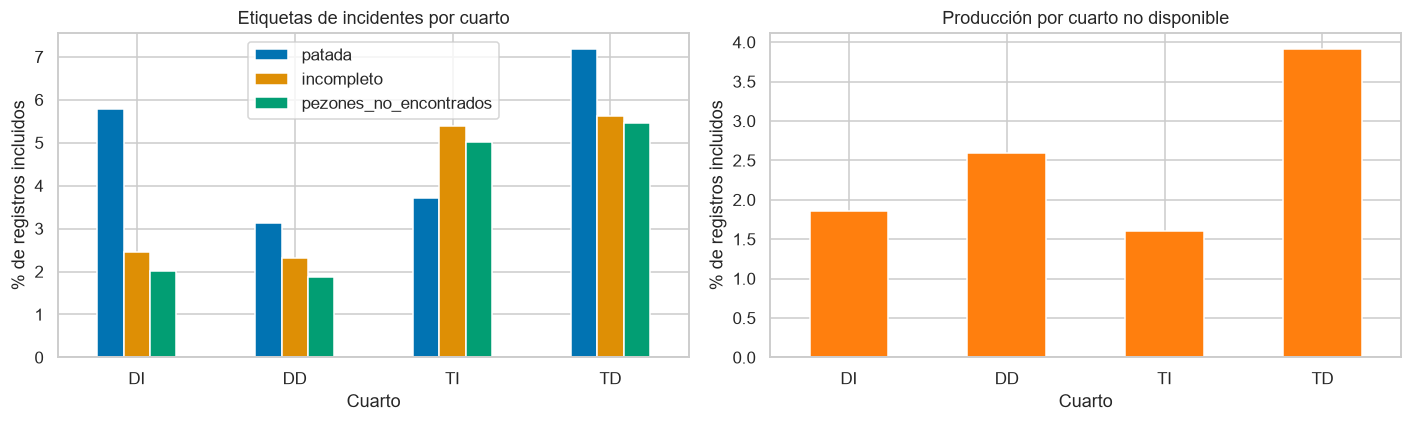

,registros,vacas,produccion_total_kg,media_kg,porcentaje_registros
misc_destino_leche,,,,,
Tanque,264914,206,"3,946,670.434",14.898,94.377
Drenaje,10418,118,"146,368.060",14.050,3.711
Divert 3,5360,198,"65,966.850",12.307,1.910
Divert 2,6,1,90.450,15.075,0.002
Divert 1,1,1,8.200,8.200,0.000


MDI disponible en 257,206/280,699 registros (91.6%).


,estado_mdi
count,"257,206.000"
mean,1.227
std,0.420
min,0.715
50%,1.101
90%,1.595
99%,2.985
max,15.356


El índice MDI se describe sin aplicar umbrales: su escala y uso deben confirmarse en el diccionario del equipo.


El cuarto con más etiquetas de patada es **TD** (7.19% de los registros). El cuarto con mayor porcentaje de producción ausente es **TD** (3.92%). La coincidencia de patrones merece investigar cobertura y eventos del equipo; no permite atribuirlos por sí sola a una condición de la vaca.

In [23]:
columnas_incidentes = ["estado_patada", "estado_incompleto", "estado_pezones_no_encontrados"]
tasas_incidentes = pd.DataFrame(index=[q.upper() for q in cuartos])
for columna in columnas_incidentes:
    texto = ordenos[columna].astype("string").fillna("").str.upper().str.replace(" ", "", regex=False)
    for cuarto in tasas_incidentes.index:
        marcado = texto.str.contains(rf"(?:^|,){cuarto}(?:,|$)", regex=True) | texto.eq("TODOS")
        tasas_incidentes.loc[cuarto, columna.removeprefix("estado_")] = marcado.mean() * 100
tasas_incidentes["sangre_positiva_pct_disponibles"] = tasas_cuarto.set_axis(tasas_incidentes.index)
tasas_incidentes["produccion_cuarto_ausente_pct"] = ordenos[columnas_cuartos].isna().mean().mul(100).to_numpy()
display(tasas_incidentes)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
tasas_incidentes[["patada", "incompleto", "pezones_no_encontrados"]].plot.bar(ax=axes[0])
axes[0].set(title="Etiquetas de incidentes por cuarto", ylabel="% de registros incluidos", xlabel="Cuarto")
axes[0].tick_params(axis="x", rotation=0)
tasas_incidentes["produccion_cuarto_ausente_pct"].plot.bar(ax=axes[1], color="tab:orange")
axes[1].set(title="Producción por cuarto no disponible", ylabel="% de registros incluidos", xlabel="Cuarto")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

por_destino = ordenos.groupby("misc_destino_leche", dropna=False).agg(
    registros=("id_vaca", "size"), vacas=("id_vaca", "nunique"),
    produccion_total_kg=("main_produccion_kg", lambda s: s.sum(min_count=1)),
    media_kg=("main_produccion_kg", "mean"))
por_destino["porcentaje_registros"] = por_destino.registros.div(len(ordenos)).mul(100)
display(por_destino.sort_values("registros", ascending=False))

mdi = ordenos[["estado_mdi", "main_produccion_kg"]].dropna()
print(f"MDI disponible en {len(mdi):,}/{len(ordenos):,} registros ({len(mdi)/len(ordenos):.1%}).")
display(mdi.estado_mdi.describe(percentiles=[0.5, 0.9, 0.99]).to_frame("estado_mdi"))
print("El índice MDI se describe sin aplicar umbrales: su escala y uso deben confirmarse en el diccionario del equipo.")
display(Markdown(
    f"El cuarto con más etiquetas de patada es **{tasas_incidentes.patada.idxmax()}** "
    f"({tasas_incidentes.patada.max():.2f}% de los registros). "
    f"El cuarto con mayor porcentaje de producción ausente es "
    f"**{tasas_incidentes.produccion_cuarto_ausente_pct.idxmax()}** "
    f"({tasas_incidentes.produccion_cuarto_ausente_pct.max():.2f}%). "
    "La coincidencia de patrones merece investigar cobertura y eventos del equipo; "
    "no permite atribuirlos por sí sola a una condición de la vaca."))


## 8. Hallazgos y límites para la siguiente etapa

- **Cobertura y esquema:** el formato nuevo aporta años de historia y más vacas,
  pero omite la acción. La regla de inclusión queda visible y conserva su origen.
- **Solapamiento de exportaciones:** se reportan los pares compatibles, la
  tolerancia de redondeo y el efecto sobre conteos y producción. Se puede cambiar
  `EXCLUIR_COINCIDENCIAS_EXPORTACION` para revisar la sensibilidad.
- **Fechas y tiempos:** las conversiones conservan las columnas originales y
  reportan ausentes y errores. Los intervalos largos se mantienen para revisión.
- **Referencia del intervalo:** la comparación con el fin del registro previo
  explica la diferencia respecto al tiempo entre inicios; se muestran los casos
  coincidentes y el error observado.
- **Patrones actualizados:** producción y cobertura mensual, asociación del
  intervalo con producción dentro de vaca, sangre e incidentes por cuarto.
- **Modelado:** separar entrenamiento y evaluación por tiempo y, según el objetivo,
  por vaca; evitar que dos exportaciones del mismo evento caigan en particiones
  distintas. Para predecir antes del ordeño, las mediciones del mismo ordeño todavía
  no estarían disponibles. Estas asociaciones no demuestran causalidad.
